# Fase 3 · Hotel Booking Demand — Notebook integral de experimentos

**Universidad de La Salle · Maestría en Inteligencia Artificial · Ciencia de Datos · 2026**

**Autores:** Carlos Arnulfo Cogua Laverde, Michael Lan ALvarez.

**Propósito:** entrenar y comparar modelos de regresión, clasificación y clustering, optimizar mediante validación cruzada, interpretar variables y entrenar un MLP con PyTorch.

## 1. Matriz de cobertura de la guía de Fase 3

| Exigencia | Implementación y evidencia que debe obtenerse |
|---|---|
| Regresión multivariable regularizada | ElasticNet ajustado, R², MAE y RMSE de Validation |
| Segundo regresor basado en ensamble | RandomForestRegressor ajustado, comparación con ElasticNet y baseline |
| Dos clasificadores distintos | RandomForestClassifier y XGBoost, Accuracy, Precision, Recall, F1, AUC-ROC y matriz de confusión |
| K-Means | K=2…10, método del codo, silueta, estabilidad y perfilamiento |
| Segundo agrupador | DBSCAN con exploración reproducible de eps/min_samples, cobertura, ruido y perfiles |
| Optimización | RandomizedSearchCV con GroupKFold o StratifiedGroupKFold sin fuga |
| Interpretabilidad | Importancia por permutación y por modelo; SHAP opcional para árboles |
| PyTorch | MLP binario, early stopping, curvas de pérdida y evaluación sobre Validation |
| Rigor y comunicación | Comparación con baselines, diagnóstico de sobreajuste, interpretaciones automáticas y conclusiones revisables |



## 2. Preparación del entorno en Colab

Tener a mano el archivo original `Hotel_Booking_Fase2_Para_Fase3.zip` sin modificarlo. La celda de carga solicitará seleccionarlo.


In [1]:
# Ejecútese en Colab antes de cualquier importación de scikit-learn.
# El comando se limita al runtime actual; no afecta archivos originales.
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError

REQUISITOS_COLAB = [
    'polars==1.35.2',
    'numpy==2.2.6',
    'scipy==1.16.2',
    'scikit-learn==1.7.2',
    'joblib==1.6.0',
    'pyarrow>=18,<24',
    'xgboost>=3.0,<4',
    'shap>=0.48,<0.60',
    'matplotlib>=3.9,<4',
    'torch>=2.3,<3',
]
# Desactivado por defecto para no cambiar paquetes sin consentimiento.
INSTALAR_DEPENDENCIAS = True
if INSTALAR_DEPENDENCIAS:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *REQUISITOS_COLAB])
    print('Instalación terminada. Si se cambió scikit-learn/NumPy, reinicie el runtime y vuelva a ejecutar desde arriba.')
else:
    print('Instalación no activada. Si faltan librerías o sklearn != 1.7.2,')
    print('cambie INSTALAR_DEPENDENCIAS a True y ejecute esta celda una vez.')


Instalación terminada. Si se cambió scikit-learn/NumPy, reinicie el runtime y vuelva a ejecutar desde arriba.


In [2]:
# Auditoría de entorno: no instala paquetes ni entrena modelos.
import sys
from importlib.metadata import PackageNotFoundError, version

PACKAGES = [
    'polars', 'numpy', 'scipy', 'scikit-learn', 'joblib',
    'matplotlib', 'xgboost', 'shap', 'torch',
]
environment = {'python': sys.version.split()[0]}
for package in PACKAGES:
    try:
        environment[package] = version(package)
    except PackageNotFoundError:
        environment[package] = None
# Se registra la versión completa para reproducibilidad, pero no se bloquea
# la ejecución por diferencias inocuas de Matplotlib, SciPy o CUDA.
# Los preprocesadores Joblib requieren la misma versión sklearn de Fase 2.
EXPECTED_SKLEARN = '1.7.2'
python_supported = sys.version_info >= (3, 11) and sys.version_info < (3, 14)
missing_packages = [name for name, value in environment.items()
                    if name != 'python' and value is None]
SKLEARN_MATCH = environment.get('scikit-learn') == EXPECTED_SKLEARN
ENVIRONMENT_READY = python_supported and not missing_packages and SKLEARN_MATCH
print('Entorno observado:', environment)
print('Python compatible (3.11-3.13):', python_supported)
print('Dependencias faltantes:', missing_packages)
print('scikit-learn coincide con Joblib de Fase 2:', SKLEARN_MATCH)
print('Entorno listo para el entrenamiento:', ENVIRONMENT_READY)
if not ENVIRONMENT_READY:
    print('ACCIÓN: ejecute la celda de instalación y reinicie el runtime si fue necesario.')

def assert_environment_ready_for_training() -> None:
    """
    Impide entrenar si Python o las dependencias no coinciden con el entorno fijado.

    Lanza ``RuntimeError`` ante cualquier incompatibilidad detectada.
    """
    if not ENVIRONMENT_READY:
        raise RuntimeError(
            'Entorno incompatible; no entrene hasta resolver las versiones.'
        )


Entorno observado: {'python': '3.13.18', 'polars': '1.35.2', 'numpy': '2.2.6', 'scipy': '1.16.2', 'scikit-learn': '1.7.2', 'joblib': '1.6.0', 'matplotlib': '3.10.0', 'xgboost': '3.4.1', 'shap': '0.54.1', 'torch': '2.14.1+cpu'}
Python compatible (3.11-3.13): True
Dependencias faltantes: []
scikit-learn coincide con Joblib de Fase 2: True
Entorno listo para el entrenamiento: True


El entorno de Colab reconoció todas las dependencias. La versión de scikit-learn (1.7.2) coincidió con la usada para guardar el preprocesador de la Fase 2. PyTorch se ejecutó en CPU.

## 3. Ingreso y verificación del paquete de Fase 2

Las particiones de la Fase 2 se cargaron desde `Hotel_Booking_Fase2_Para_Fase3.zip`.

In [3]:
# Validación y extracción controlada; no altera el ZIP ni las particiones.
import hashlib
import json
from pathlib import Path
from zipfile import ZipFile

SEED = 42
ZIP_PATH = Path('/content/Hotel_Booking_Fase2_Para_Fase3.zip')
if not ZIP_PATH.is_file():
    try:
        from google.colab import files
        print('Seleccione Hotel_Booking_Fase2_Para_Fase3.zip en su computador.')
        cargados = files.upload()
        if ZIP_PATH.name not in cargados and not ZIP_PATH.exists():
            raise FileNotFoundError('No se cargó el ZIP esperado de Fase 2.')
    except ImportError:
        raise FileNotFoundError(
            'Ejecute en Google Colab y cargue el ZIP en /content.'
        )
PROJECT_ROOT = Path('/content/fase3_hotel_booking')
INPUT_ROOT = PROJECT_ROOT / 'input_phase2'

assert ZIP_PATH.is_file(), f'No se encontró {ZIP_PATH.name}; cárguelo en Colab.'
with ZipFile(ZIP_PATH) as archive:
    assert archive.testzip() is None, 'El ZIP contiene un archivo dañado.'
    manifest = json.loads(archive.read('manifest_fase3.json'))
    expected_names = {item['path'] for item in manifest['files']} | {
        'manifest_fase3.json'
    }
    assert set(archive.namelist()) == expected_names, 'Inventario ZIP inesperado.'
    for item in manifest['files']:
        payload = archive.read(item['path'])
        assert len(payload) == item['bytes'], f'Tamaño inválido: {item["path"]}'
        assert hashlib.sha256(payload).hexdigest() == item['sha256'], (
            f'Hash inválido: {item["path"]}'
        )
    INPUT_ROOT.mkdir(parents=True, exist_ok=True)
    root_resolved = INPUT_ROOT.resolve()
    for member in archive.infolist():
        target = (INPUT_ROOT / member.filename).resolve()
        assert target == root_resolved or root_resolved in target.parents, (
            f'Ruta insegura dentro del ZIP: {member.filename}'
        )
    archive.extractall(INPUT_ROOT)
print('Paquete íntegro y extraído en:', INPUT_ROOT)


Paquete íntegro y extraído en: /content/fase3_hotel_booking/input_phase2


## 4. Contrato de datos y bloqueo del conjunto de prueba

Los tamaños esperados son: clasificación y clustering 88.923/14.821/14.820; regresión 55.791/9.299/9.298. Los objetivos son `is_canceled` y `adr`. `row_id`, `original_fingerprint` y `total_guests` quedan fuera de X; esta última se conserva solo para trazabilidad.

In [4]:
NUMERIC_FEATURES = [
    'lead_time', 'adults', 'children', 'babies', 'total_nights',
    'previous_cancellations', 'previous_bookings_not_canceled',
]
CATEGORICAL_FEATURES = [
    'hotel', 'arrival_date_month', 'meal', 'market_segment',
    'distribution_channel', 'is_repeated_guest',
    'reserved_room_type', 'customer_type',
]
CLUSTERING_FEATURES = NUMERIC_FEATURES.copy()
TARGETS = {'classification': 'is_canceled', 'regression': 'adr'}
EXCLUDED_FROM_X = {'row_id', 'original_fingerprint', 'total_guests'}
EXPECTED_ROWS = {
    'classification': {'train': 88923, 'validation': 14821, 'test': 14820},
    'regression': {'train': 55791, 'validation': 9299, 'test': 9298},
    'clustering': {'train': 88923, 'validation': 14821, 'test': 14820},
}
ALLOW_TEST_EVALUATION = False  # Cambiar solo tras aprobación del modelo congelado.
RUN_COSTLY_TRAINING = True  # Ejecuta modelos y métricas reales; cambiar a False para diagnóstico rápido.
CV_SPLITS = 3  # Presupuesto provisional autorizado; ampliable solo con aprobación.
COLAB_N_JOBS = 1  # Ajustes paralelos limitados para controlar RAM.
N_ITER_SEARCH = 3  # Modo rápido: 3 configuraciones x 3 folds/modelo; búsqueda exploratoria reproducible.
MAX_SILHOUETTE_SAMPLE = 2500
MAX_SHAP_ROWS = 500
MAX_SHAP_DENSE_GB = 0.25
MAX_PERMUTATION_ROWS = 800
MAX_PERMUTATION_REPEATS = 3
MAX_PERMUTATION_SCORED_ROWS = 200000
DBSCAN_SAMPLE_STAGES = (3500, 5000, 10000)
MAX_DBSCAN_PAIRWISE_GB = 2.0
ALLOW_FULL_DBSCAN = False
TEST_AUTHORIZATION_ID = None  # Se asigna manualmente tras autorización escrita.
PRIMARY_CLASSIFICATION_THRESHOLD = 0.5
CLASSIFICATION_THRESHOLD_POLICY = 'primary_0.5_secondary_validation_f1'


In [5]:
# Carga autorizada: Train/Validation completos; Test solo esquema, conteo y huella.
import polars as pl

DATA_ROOT = INPUT_ROOT / 'data' / 'processed'
datasets = {}
sealed_test_metadata = {}
SEALED_TEST_PATHS = {}
for task, splits in EXPECTED_ROWS.items():
    datasets[task] = {}
    fingerprints = {}
    expected_features = (
        CLUSTERING_FEATURES
        if task == 'clustering'
        else NUMERIC_FEATURES + CATEGORICAL_FEATURES
    )
    for split in ('train', 'validation'):
        path = DATA_ROOT / f'{task}_{split}.parquet'
        frame = pl.read_parquet(path)
        assert frame.height == splits[split], (task, split, frame.height)
        assert {'row_id', 'original_fingerprint'} <= set(frame.columns)
        assert set(expected_features) <= set(frame.columns)
        if task in TARGETS:
            assert TARGETS[task] in frame.columns
        datasets[task][split] = frame
        fingerprints[split] = set(frame['original_fingerprint'])

    # Test no se carga completo y nunca se selecciona su objetivo en esta etapa.
    test_path = DATA_ROOT / f'{task}_test.parquet'
    test_scan = pl.scan_parquet(test_path)
    test_schema = test_scan.collect_schema()
    assert {'row_id', 'original_fingerprint'} <= set(test_schema.names())
    assert set(expected_features) <= set(test_schema.names())
    if task in TARGETS:
        assert TARGETS[task] in test_schema.names()  # Solo nombre/tipo; no valores.
    test_rows = test_scan.select(pl.len().alias('rows')).collect().item()
    assert test_rows == splits['test'], (task, 'test', test_rows)
    test_fingerprints = set(
        test_scan.select('original_fingerprint').collect()['original_fingerprint']
    )
    assert not (fingerprints['train'] & fingerprints['validation'])
    assert not (fingerprints['train'] & test_fingerprints)
    assert not (fingerprints['validation'] & test_fingerprints)
    sealed_test_metadata[task] = {
        'rows': int(test_rows), 'columns': tuple(test_schema.names()),
        'target_values_read': False, 'fingerprint_overlap': 0,
    }
    SEALED_TEST_PATHS[task] = test_path
    del test_scan, test_fingerprints

assert all('test' not in parts for parts in datasets.values())
print('Train/Validation cargados; Test sellado sin leer objetivos.')


Train/Validation cargados; Test sellado sin leer objetivos.


### Reservas incluidas en el análisis

El archivo pasó la verificación de integridad y se recuperaron las particiones de la Fase 2. En validación se usaron 14.821 reservas para estudiar la cancelación y 9.299 para estimar la tarifa diaria media (ADR). La diferencia corresponde a las 5.522 reservas canceladas. Por eso el error de tarifa describe únicamente las reservas que se mantuvieron.

## 5. Preprocesamiento dentro de validación cruzada

Los Joblib de Fase 2 se conservarán como evidencia de reproducción del baseline. Para optimizar modelos avanzados se construirá un Pipeline nuevo: mediana y StandardScaler para numéricas; moda y OneHotEncoder para nominales. Cada fold ajustará sus propias estadísticas.

- Regresión: `GroupKFold` de 3 folds con `original_fingerprint`.
- Clasificación: `StratifiedGroupKFold` de 3 folds.
- Auditoría ligera: grupos disjuntos, cobertura completa y ambas clases en cada fold de clasificación.
- Presupuesto provisional: 3 configuraciones por modelo; cualquier ampliación requiere autorización.
- Métricas primarias declaradas antes de la búsqueda.
- Ningún estimador verá validación o test durante CV.

In [6]:
# Infraestructura común. Definir objetos no ajusta modelos ni consulta test.
import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

REGRESSION_SCORING = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2',
}
CLASSIFICATION_SCORING = {
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
    'accuracy': 'accuracy',
}

def assert_training_enabled(operation: str) -> None:
    """
    Verifica las puertas de coste y compatibilidad antes de una operación pesada.

    Lanza ``RuntimeError`` si la ejecución no fue autorizada.
    """
    if not RUN_COSTLY_TRAINING:
        raise RuntimeError(
            f'{operation} bloqueado: revise el presupuesto y cambie '
            'RUN_COSTLY_TRAINING solo después de la aprobación.'
        )
    assert_environment_ready_for_training()

def assert_runtime_helpers_available() -> None:
    """
    Comprueba que las celdas compartidas fueron ejecutadas antes de entrenar.

    Lanza ``RuntimeError`` con los símbolos faltantes en ejecución interactiva.
    """
    required = {
        'prepare_run_directory', 'search_best_summary', 'atomic_write_json',
        'joblib',
    }
    missing = sorted(name for name in required if name not in globals())
    if missing:
        raise RuntimeError(
            f'Ejecute primero todas las celdas de definición; faltan: {missing}'
        )

def make_model_preprocessor(*, sparse_output: bool = True) -> ColumnTransformer:
    """
    Construye el preprocesamiento supervisado que se ajustará dentro de cada fold.

    Retorna un ``ColumnTransformer`` sin ajustar para evitar fuga de información.
    """
    # Todo estadístico se aprende dentro del fold mediante el Pipeline.
    numeric = Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
    ])
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=sparse_output)),
    ])
    return ColumnTransformer(
        [('numeric', numeric, NUMERIC_FEATURES),
         ('categorical', categorical, CATEGORICAL_FEATURES)],
        remainder='drop',
        sparse_threshold=1.0 if sparse_output else 0.0,
        verbose_feature_names_out=True,
    )

def prepare_supervised_X(frame: pl.DataFrame) -> pl.DataFrame:
    """
    Selecciona predictores autorizados y representa categorías como texto.

    No incluye objetivos, identificadores ni variables excluidas por temporalidad.
    """
    # Los nominales se entregan como texto; no se interpretan como magnitudes.
    return frame.select(NUMERIC_FEATURES + CATEGORICAL_FEATURES).with_columns([
        pl.col(column).cast(pl.String).fill_null('__MISSING__')
        for column in CATEGORICAL_FEATURES
    ])

def supervised_split(task: str, split: str):
    """
    Expone X, y y grupos únicamente para Train o Validation de una tarea.

    Lanza ``RuntimeError`` ante cualquier intento de solicitar Test.
    """
    if split not in {'train', 'validation'}:
        raise RuntimeError(
            'Esta función solo expone Train/Validation; Test usa la puerta final.'
        )
    frame = datasets[task][split]
    return (
        prepare_supervised_X(frame),
        frame[TARGETS[task]].to_numpy(),
        frame['original_fingerprint'].to_numpy(),
    )

REGRESSION_CV = GroupKFold(n_splits=CV_SPLITS)
CLASSIFICATION_CV = StratifiedGroupKFold(
    n_splits=CV_SPLITS, shuffle=True, random_state=SEED
)

def validate_grouped_cv(task: str) -> pl.DataFrame:
    """
    Audita disyunción, cobertura y clases de los folds agrupados de Train.

    Retorna una tabla por fold sin ajustar ningún modelo.
    """
    frame = datasets[task]['train']
    y = frame[TARGETS[task]].to_numpy()
    groups = frame['original_fingerprint'].to_numpy()
    splitter = CLASSIFICATION_CV if task == 'classification' else REGRESSION_CV
    X_placeholder = np.zeros((frame.height, 1), dtype=np.int8)
    validation_groups_seen, rows = set(), []
    for fold, (train_index, validation_index) in enumerate(
        splitter.split(X_placeholder, y, groups), start=1
    ):
        train_groups = set(groups[train_index])
        validation_groups = set(groups[validation_index])
        assert train_groups.isdisjoint(validation_groups), (task, fold)
        assert validation_groups_seen.isdisjoint(validation_groups), (task, fold)
        validation_groups_seen.update(validation_groups)
        row = {
            'task': task, 'fold': fold,
            'train_rows': len(train_index),
            'validation_rows': len(validation_index),
            'train_groups': len(train_groups),
            'validation_groups': len(validation_groups),
            'group_overlap': 0,
        }
        if task == 'classification':
            train_classes = set(np.unique(y[train_index]))
            validation_classes = set(np.unique(y[validation_index]))
            assert train_classes == {0, 1}, (task, fold, 'train', train_classes)
            assert validation_classes == {0, 1}, (
                task, fold, 'validation', validation_classes
            )
            row['train_positive_rate'] = float(np.mean(y[train_index]))
            row['validation_positive_rate'] = float(np.mean(y[validation_index]))
        rows.append(row)
    assert validation_groups_seen == set(groups), (task, 'incomplete_group_coverage')
    assert len(rows) == CV_SPLITS
    return pl.DataFrame(rows)

CV_FOLD_AUDIT = {
    task: validate_grouped_cv(task)
    for task in ('regression', 'classification')
}
print('CV agrupada validada sin solapamiento:', CV_FOLD_AUDIT)

def colab_compatibility_smoke_test() -> dict:
    """
    Ejecuta comprobaciones ligeras de imports, Joblib y transformaciones en Colab.

    No entrena estimadores ni lee valores del conjunto Test.
    """
    # Permitido: imports, carga Joblib verificada y transformación de muestras pequeñas.
    assert_environment_ready_for_training()
    import joblib as local_joblib
    import shap as local_shap
    import torch as local_torch
    from sklearn.base import clone
    from xgboost import XGBClassifier

    train = datasets['classification']['train'].head(128)
    validation = datasets['classification']['validation'].head(32)
    preprocessor = make_model_preprocessor(sparse_output=True)
    transformed_train = preprocessor.fit_transform(prepare_supervised_X(train))
    transformed_validation = preprocessor.transform(
        prepare_supervised_X(validation)
    )
    clone(XGBClassifier(n_estimators=1, tree_method='hist', random_state=SEED))
    tensor_shape = tuple(local_torch.nn.Linear(4, 1)(local_torch.zeros(2, 4)).shape)
    phase2_preprocessor = local_joblib.load(
        INPUT_ROOT / 'preprocessors' / 'classification_preprocessor.joblib'
    )
    phase2_shape = phase2_preprocessor.transform(
        prepare_supervised_X(validation)
    ).shape
    return {
        'train_shape': transformed_train.shape,
        'validation_shape': transformed_validation.shape,
        'phase2_preprocessor_shape': phase2_shape,
        'torch_smoke_shape': tensor_shape,
        'shap_version': local_shap.__version__,
        'test_read': False, 'model_fit': False,
    }


CV agrupada validada sin solapamiento: {'regression': shape: (3, 7)
┌────────────┬──────┬────────────┬─────────────────┬──────────────┬────────────────┬───────────────┐
│ task       ┆ fold ┆ train_rows ┆ validation_rows ┆ train_groups ┆ validation_gro ┆ group_overlap │
│ ---        ┆ ---  ┆ ---        ┆ ---             ┆ ---          ┆ ups            ┆ ---           │
│ str        ┆ i64  ┆ i64        ┆ i64             ┆ i64          ┆ ---            ┆ i64           │
│            ┆      ┆            ┆                 ┆              ┆ i64            ┆               │
╞════════════╪══════╪════════════╪═════════════════╪══════════════╪════════════════╪═══════════════╡
│ regression ┆ 1    ┆ 37194      ┆ 18597           ┆ 31328        ┆ 15663          ┆ 0             │
│ regression ┆ 2    ┆ 37194      ┆ 18597           ┆ 31327        ┆ 15664          ┆ 0             │
│ regression ┆ 3    ┆ 37194      ┆ 18597           ┆ 31327        ┆ 15664          ┆ 0             │
└────────────┴──────┴──

### Qué muestran las particiones de validación cruzada

En regresión, cada partición evaluó 18.597 reservas. En clasificación, la proporción de cancelaciones varió entre el 35,9 % y el 38,2 % en los tres subconjuntos de evaluación. La columna `group_overlap` fue cero en todos los casos. Así, las reservas con la misma huella quedaron juntas y ningún modelo se evaluó en un pliegue con una copia exacta que ya hubiera visto al entrenar.

## 6. Regresión avanzada

La tarea estima ADR únicamente en reservas no canceladas, por lo que sus conclusiones son condicionales a esa población y no describen tarifas de todas las reservas. ElasticNet aporta un referente multivariable regularizado ante predictores correlacionados y codificación one-hot; sus coeficientes no se interpretan causalmente. Random Forest permite relaciones no lineales e interacciones sin imponer forma funcional, con mayor riesgo de sobreajuste y menor transparencia.

### 6.1 ElasticNet
Regresión multivariable regularizada. Optimizar `alpha` y `l1_ratio` con CV agrupada.

### 6.2 Random Forest Regressor
Optimizar número de árboles, profundidad, tamaños mínimos de nodo y selección de variables.

### 6.3 Evaluación
RMSE es el criterio primario de selección porque penaliza errores grandes en la cola de ADR; MAE, en unidades de ADR, resume el error absoluto típico y es más robusto; R² cuantifica mejora frente a la media y puede ser negativo. Comparar con Dummy y regresión lineal de Fase 2. La elección usa Train/CV y Validation; Test solo después de congelar la solución.

Los gráficos de tarifa observada, tarifa estimada y residuos se interpretan en la sección 14.

In [7]:
from scipy.stats import loguniform, randint
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import RandomizedSearchCV

REGRESSION_SEARCH_SPACE_SPEC = {
    'elastic_net': {
        'alpha': {'distribution': 'loguniform', 'low': 1e-4, 'high': 1e2},
        'l1_ratio': {'values': np.linspace(0.05, 0.95, 19).tolist()},
        'tol': {'values': [1e-4, 5e-4, 1e-3]},
    },
    'random_forest_regressor': {
        'n_estimators': {'distribution': 'randint', 'low': 35, 'high': 91},
        'max_depth': {'values': [6, 10, 14, 18]},
        'min_samples_split': {'distribution': 'randint', 'low': 2, 'high': 21},
        'min_samples_leaf': {'distribution': 'randint', 'low': 1, 'high': 11},
        'max_features': {'values': [1.0, 'sqrt', 0.5, 0.75]},
    },
}

def build_regression_searches() -> dict[str, RandomizedSearchCV]:
    """
    Define las búsquedas reproducibles de ElasticNet y Random Forest Regressor.

    Retorna objetos sin ajustar con RMSE como criterio primario de selección.
    """
    elastic_pipeline = Pipeline([
        ('preprocess', make_model_preprocessor(sparse_output=True)),
        ('model', ElasticNet(max_iter=20000, random_state=SEED)),
    ])
    forest_pipeline = Pipeline([
        ('preprocess', make_model_preprocessor(sparse_output=True)),
        ('model', RandomForestRegressor(
            random_state=SEED, n_jobs=1, bootstrap=True
        )),
    ])
    common = dict(
        n_iter=N_ITER_SEARCH, scoring=REGRESSION_SCORING, refit='rmse',
        cv=REGRESSION_CV, random_state=SEED, n_jobs=COLAB_N_JOBS,
        return_train_score=True, error_score='raise', verbose=2,
        pre_dispatch=COLAB_N_JOBS,
    )
    return {
        'elastic_net': RandomizedSearchCV(
            elastic_pipeline,
            {
                'model__alpha': loguniform(1e-4, 1e2),
                'model__l1_ratio': np.linspace(0.05, 0.95, 19),
                'model__tol': [1e-4, 5e-4, 1e-3],
            },
            **common,
        ),
        'random_forest_regressor': RandomizedSearchCV(
            forest_pipeline,
            {
                'model__n_estimators': randint(35, 91),
                'model__max_depth': [6, 10, 14, 18],
                'model__min_samples_split': randint(2, 21),
                'model__min_samples_leaf': randint(1, 11),
                'model__max_features': [1.0, 'sqrt', 0.5, 0.75],
            },
            **common,
        ),
    }

def regression_metrics(model, frame: pl.DataFrame) -> dict[str, float]:
    """
    Calcula MAE, RMSE y R² para un modelo de regresión ya ajustado.

    Las unidades de MAE y RMSE corresponden a ADR; R² puede ser negativo.
    """
    y_true = frame['adr'].to_numpy()
    y_pred = model.predict(prepare_supervised_X(frame))
    return {
        'mae': float(mean_absolute_error(y_true, y_pred)),
        'rmse': float(root_mean_squared_error(y_true, y_pred)),
        'r2': float(r2_score(y_true, y_pred)),
    }

def plot_regression_diagnostics(model, frame: pl.DataFrame):
    """
    Grafica valores reales frente a predichos y la distribución de residuos.

    Retorna una figura construida exclusivamente con predicciones calculadas.
    """
    y_true = frame['adr'].to_numpy()
    y_pred = model.predict(prepare_supervised_X(frame))
    residuals = y_true - y_pred
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
    axes[0].scatter(y_true, y_pred, s=9, alpha=0.35)
    low, high = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    axes[0].plot([low, high], [low, high], linestyle='--', color='black')
    axes[0].set(xlabel='ADR real', ylabel='ADR predicho', title='Real vs. predicho')
    axes[1].hist(residuals, bins=50)
    axes[1].set(xlabel='Residuo (real - predicho)', ylabel='Frecuencia',
                title='Distribución de residuos')
    return fig

def run_regression_searches():
    """
    Ejecuta o reanuda las búsquedas de regresión bajo presupuesto autorizado.

    Persiste CV, mejor estimador y métricas de Validation por configuración.
    """
    assert_training_enabled('Búsquedas de regresión')
    assert_runtime_helpers_available()
    X_train, y_train, groups = supervised_split('regression', 'train')
    searches = build_regression_searches()
    audit_search_budget(searches)
    outputs = {}
    for name, search in searches.items():
        configuration = {
            'task': 'regression', 'model': name,
            'n_iter': N_ITER_SEARCH, 'cv_splits': CV_SPLITS,
            'resume_granularity': 'completed_model_search_only',
            'parameter_space': REGRESSION_SEARCH_SPACE_SPEC[name],
        }
        run_directory, digest = prepare_run_directory(name, configuration)
        if completed_run(run_directory, digest):
            outputs[name] = {
                'status': 'resumed',
                'estimator': joblib.load(run_directory / 'model.joblib'),
                'summary': json.loads(
                    (run_directory / 'summary.json').read_text(encoding='utf-8')
                ),
            }
            continue
        print(f'\n>>> INICIO: {name} | {N_ITER_SEARCH} configuraciones × {CV_SPLITS} folds', flush=True)
        search.fit(X_train, y_train, groups=groups)
        print(f'>>> BÚSQUEDA TERMINADA: {name}; guardando resultados...', flush=True)
        validation = regression_metrics(
            search.best_estimator_, datasets['regression']['validation']
        )
        summary = search_best_summary(name, search, 'regression')
        summary['validation'] = validation
        atomic_write_json(run_directory / 'cv_results.json', search.cv_results_)
        save_sklearn_checkpoint(
            run_directory, search.best_estimator_, summary, digest
        )
        print(f'>>> GUARDADO: {name}', flush=True)
        outputs[name] = {
            'status': 'completed', 'estimator': search.best_estimator_,
            'summary': summary, 'search': search,
        }
    return outputs


## 7. Clasificación avanzada

La clasificación es retrospectiva sobre la fotografía previa a la llegada; no demuestra una alerta disponible al crear la reserva. Random Forest ofrece bagging, interacciones y robustez no lineal; XGBoost agrega árboles secuencialmente y regulariza el error residual, pero requiere mayor control de complejidad y coste. Ninguna importancia se interpreta como causal.

### 7.1 Random Forest Classifier
Evaluar complejidad, regularización estructural y posible `class_weight`, sin asumir desbalance severo.

### 7.2 XGBoost Classifier
Optimizar árboles, profundidad, learning rate, subsampling y regularización.

### 7.3 Evaluación y umbral
La clase positiva es 1=cancelación. ROC-AUC es el criterio primario de ranking y no depende de un único umbral; F1, recall, precision, accuracy y matriz de confusión complementan su lectura. La comparación primaria de RF, XGBoost y MLP usa umbral 0,5; cualquier umbral alternativo es un análisis secundario elegido solo con Validation y congelado antes de Test.

Las matrices de confusión y las curvas ROC se interpretan en la sección 14.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

CLASSIFICATION_SEARCH_SPACE_SPEC = {
    'random_forest_classifier': {
        'n_estimators': {'distribution': 'randint', 'low': 35, 'high': 91},
        'max_depth': {'values': [6, 10, 14, 18]},
        'min_samples_split': {'distribution': 'randint', 'low': 2, 'high': 21},
        'min_samples_leaf': {'distribution': 'randint', 'low': 1, 'high': 11},
        'max_features': {'values': ['sqrt', 'log2', 0.5, 0.75]},
        'class_weight': {'values': [None, 'balanced']},
    },
    'xgboost_classifier': {
        'n_estimators': {'distribution': 'randint', 'low': 60, 'high': 141},
        'max_depth': {'distribution': 'randint', 'low': 3, 'high': 7},
        'learning_rate': {'distribution': 'loguniform', 'low': 0.01, 'high': 0.3},
        'subsample': {'values': np.linspace(0.6, 1.0, 5).tolist()},
        'colsample_bytree': {'values': np.linspace(0.6, 1.0, 5).tolist()},
        'min_child_weight': {'distribution': 'randint', 'low': 1, 'high': 11},
        'reg_alpha': {'distribution': 'loguniform', 'low': 1e-5, 'high': 10.0},
        'reg_lambda': {'distribution': 'loguniform', 'low': 1e-3, 'high': 100.0},
    },
}

def build_classification_searches() -> dict[str, RandomizedSearchCV]:
    """
    Define búsquedas para Random Forest y XGBoost con CV estratificada por grupos.

    Retorna búsquedas sin ajustar y usa ROC-AUC como criterio primario.
    """
    # Importación diferida: la auditoría de entorno debe validar XGBoost antes.
    from xgboost import XGBClassifier

    forest_pipeline = Pipeline([
        ('preprocess', make_model_preprocessor(sparse_output=True)),
        ('model', RandomForestClassifier(
            random_state=SEED, n_jobs=1, class_weight=None
        )),
    ])
    xgb_pipeline = Pipeline([
        ('preprocess', make_model_preprocessor(sparse_output=True)),
        ('model', XGBClassifier(
            objective='binary:logistic', eval_metric='logloss',
            tree_method='hist', random_state=SEED, n_jobs=1,
            verbosity=0,
        )),
    ])
    common = dict(
        n_iter=N_ITER_SEARCH, scoring=CLASSIFICATION_SCORING,
        refit='roc_auc', cv=CLASSIFICATION_CV, random_state=SEED,
        n_jobs=COLAB_N_JOBS, return_train_score=True,
        error_score='raise', verbose=2, pre_dispatch=COLAB_N_JOBS,
    )
    return {
        'random_forest_classifier': RandomizedSearchCV(
            forest_pipeline,
            {
                'model__n_estimators': randint(35, 91),
                'model__max_depth': [6, 10, 14, 18],
                'model__min_samples_split': randint(2, 21),
                'model__min_samples_leaf': randint(1, 11),
                'model__max_features': ['sqrt', 'log2', 0.5, 0.75],
                'model__class_weight': [None, 'balanced'],
            },
            **common,
        ),
        'xgboost_classifier': RandomizedSearchCV(
            xgb_pipeline,
            {
                'model__n_estimators': randint(60, 141),
                'model__max_depth': randint(3, 7),
                'model__learning_rate': loguniform(0.01, 0.3),
                'model__subsample': np.linspace(0.6, 1.0, 5),
                'model__colsample_bytree': np.linspace(0.6, 1.0, 5),
                'model__min_child_weight': randint(1, 11),
                'model__reg_alpha': loguniform(1e-5, 10.0),
                'model__reg_lambda': loguniform(1e-3, 100.0),
            },
            **common,
        ),
    }

def classification_metrics(
    model, frame: pl.DataFrame, threshold: float = PRIMARY_CLASSIFICATION_THRESHOLD
) -> dict[str, object]:
    """
    Calcula métricas binarias y matriz de confusión para cancelación positiva.

    ROC-AUC usa probabilidades; las demás métricas dependen del umbral indicado.
    """
    y_true = frame['is_canceled'].to_numpy()
    probability = model.predict_proba(prepare_supervised_X(frame))[:, 1]
    prediction = (probability >= threshold).astype(np.int8)
    return {
        'threshold': float(threshold),
        'accuracy': float(accuracy_score(y_true, prediction)),
        'precision': float(precision_score(y_true, prediction, zero_division=0)),
        'recall': float(recall_score(y_true, prediction, zero_division=0)),
        'f1': float(f1_score(y_true, prediction, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, probability)),
        'confusion_matrix': confusion_matrix(
            y_true, prediction, labels=[0, 1]
        ).tolist(),
    }

def plot_classification_diagnostics(
    model, frame: pl.DataFrame, threshold: float = PRIMARY_CLASSIFICATION_THRESHOLD
):
    """
    Genera la matriz de confusión y la curva ROC de un clasificador ajustado.

    Retorna una figura sin modificar el modelo ni seleccionar con Test.
    """
    y_true = frame['is_canceled'].to_numpy()
    probability = model.predict_proba(prepare_supervised_X(frame))[:, 1]
    prediction = (probability >= threshold).astype(np.int8)
    matrix = confusion_matrix(y_true, prediction, labels=[0, 1])
    fpr, tpr, _ = roc_curve(y_true, probability)
    auc_value = roc_auc_score(y_true, probability)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
    axes[0].imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            axes[0].text(column, row, str(matrix[row, column]),
                         ha='center', va='center')
    axes[0].set(xticks=[0, 1], yticks=[0, 1], xlabel='Predicción',
                ylabel='Clase real', title=f'Matriz · umbral {threshold:.2f}')
    axes[1].plot(fpr, tpr, label=f'ROC-AUC={auc_value:.3f}')
    axes[1].plot([0, 1], [0, 1], linestyle='--', color='black')
    axes[1].set(xlabel='Falsos positivos', ylabel='Verdaderos positivos',
                title='Curva ROC')
    axes[1].legend()
    return fig

def run_classification_searches():
    """
    Ejecuta o reanuda búsquedas de clasificación usando Train y Validation.

    Persiste resultados por hash y nunca consulta el conjunto Test.
    """
    assert_training_enabled('Búsquedas de clasificación')
    assert_runtime_helpers_available()
    X_train, y_train, groups = supervised_split('classification', 'train')
    searches = build_classification_searches()
    audit_search_budget(searches)
    outputs = {}
    for name, search in searches.items():
        configuration = {
            'task': 'classification', 'model': name,
            'n_iter': N_ITER_SEARCH, 'cv_splits': CV_SPLITS,
            'resume_granularity': 'completed_model_search_only',
            'parameter_space': CLASSIFICATION_SEARCH_SPACE_SPEC[name],
        }
        run_directory, digest = prepare_run_directory(name, configuration)
        if completed_run(run_directory, digest):
            outputs[name] = {
                'status': 'resumed',
                'estimator': joblib.load(run_directory / 'model.joblib'),
                'summary': json.loads(
                    (run_directory / 'summary.json').read_text(encoding='utf-8')
                ),
            }
            continue
        print(f'\n>>> INICIO: {name} | {N_ITER_SEARCH} configuraciones × {CV_SPLITS} folds', flush=True)
        search.fit(X_train, y_train, groups=groups)
        print(f'>>> BÚSQUEDA TERMINADA: {name}; guardando resultados...', flush=True)
        validation = classification_metrics(
            search.best_estimator_, datasets['classification']['validation']
        )
        summary = search_best_summary(name, search, 'classification')
        summary['validation'] = validation
        atomic_write_json(run_directory / 'cv_results.json', search.cv_results_)
        save_sklearn_checkpoint(
            run_directory, search.best_estimator_, summary, digest
        )
        print(f'>>> GUARDADO: {name}', flush=True)
        outputs[name] = {
            'status': 'completed', 'estimator': search.best_estimator_,
            'summary': summary, 'search': search,
        }
    return outputs


## 8. Clustering y segmentación

### 8.1 K-Means
Evaluar K=2..10 con inercia, codo, silueta y estabilidad ARI entre tres semillas. La selección automática solo considera el entorno ±1 del codo, silueta a menos de 0,02 del máximo y ARI medio ≥0,85; si ningún K cumple, se exige revisión manual. Perfilar en unidades originales; PCA se reserva para visualización.

### 8.2 DBSCAN
Explorar `eps` mediante cuantiles reproducibles de la distancia al k-ésimo vecino y `min_samples` en {5,10,20}. Las muestras autorizadas de Train son 3.500, 5.000 y 10.000 filas, con hash de índices y límite preventivo de 2 GiB en el peor caso. Seleccionar solo configuraciones con 2–20 clústeres, cobertura ≥50 %, ruido ≤50 % y silueta definida. El ajuste completo requiere `ALLOW_FULL_DBSCAN=True` y autorización independiente tras el piloto de RAM.

### 8.3 Interpretación
Comparar estabilidad, perfiles y utilidad práctica sin usar `is_canceled` o `adr` para construir los clústeres. El perfil final debe reportar tamaño y proporción de cada segmento, mediana e IQR de variables numéricas, moda o proporciones de variables categóricas y una descripción operativa prudente. Un segmento solo se considera útil si es estable, distinguible y accionable; no se asignarán etiquetas comerciales sin evidencia.

La sección 15 presenta la comparación de K, los perfiles de reserva y los resultados del piloto DBSCAN.

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

def make_clustering_preprocessor() -> Pipeline:
    """
    Construye imputación por mediana y escalamiento para variables de clustering.

    Retorna un pipeline sin ajustar que solo debe aprender de Train.
    """
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
    ])

def clustering_train_matrix():
    """
    Ajusta el preprocesamiento no supervisado sobre Train y genera su matriz.

    Retorna datos, matriz ``float32`` y preprocesador ajustado.
    """
    frame = datasets['clustering']['train']
    preprocessor = make_clustering_preprocessor()
    matrix = preprocessor.fit_transform(
        frame.select(CLUSTERING_FEATURES).to_numpy()
    )
    return frame, matrix.astype(np.float32, copy=False), preprocessor

KMEANS_STABILITY_SEEDS = (SEED, SEED + 1000, SEED + 2000)

def run_kmeans_analysis(k_values=range(2, 11)):
    """
    Evalúa K-Means mediante inercia, silueta y estabilidad entre semillas.

    Persiste modelos y resultados bajo un hash reproducible de configuración.
    """
    assert_training_enabled('Análisis K-Means')
    assert_runtime_helpers_available()
    k_values = tuple(int(value) for value in k_values)
    configuration = {
        'algorithm': 'kmeans', 'k_values': list(k_values),
        'stability_seeds': list(KMEANS_STABILITY_SEEDS),
        'n_init': 10, 'max_iter': 500,
        'silhouette_sample': MAX_SILHOUETTE_SAMPLE,
    }
    run_directory, digest = prepare_run_directory('kmeans', configuration)
    frame, matrix, preprocessor = clustering_train_matrix()
    bundle_path = run_directory / 'kmeans_bundle.joblib'
    results_path = run_directory / 'kmeans_results.json'
    if bundle_path.exists() and results_path.exists():
        bundle = joblib.load(bundle_path)
        if bundle.get('configuration_hash') != digest:
            raise RuntimeError('Bundle K-Means incompatible.')
        return (pl.DataFrame(json.loads(results_path.read_text(encoding='utf-8'))),
                bundle['models'], bundle['preprocessor'], frame, matrix)
    rows, models = [], {}
    for k in k_values:
        labels_by_seed, inertias, iterations = [], [], []
        for run_seed in KMEANS_STABILITY_SEEDS:
            model = KMeans(
                n_clusters=k, init='k-means++', n_init=10,
                max_iter=500, random_state=run_seed,
            )
            labels = model.fit_predict(matrix)
            labels_by_seed.append(labels)
            inertias.append(float(model.inertia_))
            iterations.append(int(model.n_iter_))
            if run_seed == SEED:
                models[int(k)] = model
        stability_values = [
            adjusted_rand_score(labels_by_seed[i], labels_by_seed[j])
            for i in range(len(labels_by_seed))
            for j in range(i + 1, len(labels_by_seed))
        ]
        reference_labels = labels_by_seed[0]
        score = silhouette_score(
            matrix, reference_labels, metric='euclidean',
            sample_size=min(MAX_SILHOUETTE_SAMPLE, len(matrix)),
            random_state=SEED,
        )
        rows.append({
            'k': int(k), 'inertia': float(np.mean(inertias)),
            'inertia_std': float(np.std(inertias)),
            'silhouette': float(score),
            'stability_ari_mean': float(np.mean(stability_values)),
            'stability_ari_min': float(np.min(stability_values)),
            'iterations_mean': float(np.mean(iterations)),
        })
    results = pl.DataFrame(rows)
    bundle_temp = run_directory / 'kmeans_bundle.joblib.tmp'
    joblib.dump(
        {'configuration_hash': digest, 'models': models,
         'preprocessor': preprocessor}, bundle_temp, compress=3
    )
    bundle_temp.replace(bundle_path)
    atomic_write_json(results_path, rows)
    return results, models, preprocessor, frame, matrix

def select_kmeans_k(
    results: pl.DataFrame, silhouette_tolerance: float = 0.02,
    minimum_stability: float = 0.85,
) -> dict[str, object]:
    """
    Selecciona K combinando codo, tolerancia de silueta y estabilidad ARI.

    Retorna revisión manual cuando ningún candidato cumple todos los criterios.
    """
    ordered = results.sort('k')
    k = ordered['k'].to_numpy().astype(float)
    inertia = ordered['inertia'].to_numpy().astype(float)
    if len(k) < 3 or np.ptp(k) == 0 or np.ptp(inertia) == 0:
        raise ValueError('Se requieren al menos tres K con inercias distintas.')
    x = (k - k.min()) / np.ptp(k)
    y = (inertia - inertia.min()) / np.ptp(inertia)
    elbow_distance = np.abs(x + y - 1.0) / np.sqrt(2.0)
    elbow_k = int(k[int(np.argmax(elbow_distance))])
    max_silhouette = float(ordered['silhouette'].max())
    neighborhood = {elbow_k - 1, elbow_k, elbow_k + 1}
    eligible = (
        ordered.filter(
            pl.col('k').is_in(sorted(neighborhood))
            & (pl.col('silhouette') >= max_silhouette - silhouette_tolerance)
            & (pl.col('stability_ari_mean') >= minimum_stability)
        )
        .sort(
            ['silhouette', 'stability_ari_mean', 'k'],
            descending=[True, True, False],
        )
    )
    selected_k = None if eligible.is_empty() else int(eligible['k'][0])
    return {
        'selected_k': selected_k, 'elbow_k': elbow_k,
        'max_silhouette': max_silhouette,
        'silhouette_tolerance': silhouette_tolerance,
        'minimum_stability': minimum_stability,
        'decision': (
            'selected' if selected_k is not None
            else 'manual_review_required_no_k_met_all_criteria'
        ),
    }

def kmeans_validation_analysis(model, preprocessor) -> dict[str, object]:
    """
    Evalúa estabilidad descriptiva de K-Means en Validation sin reajustar.

    Retorna silueta, tamaños y etiquetas predichas.
    """
    # Solo transform/predict: no reajusta K-Means ni el preprocesador.
    frame = datasets['clustering']['validation']
    matrix = preprocessor.transform(
        frame.select(CLUSTERING_FEATURES).to_numpy()
    ).astype(np.float32, copy=False)
    labels = model.predict(matrix)
    clusters = len(np.unique(labels))
    score = None
    if clusters >= 2:
        score = float(silhouette_score(
            matrix, labels,
            sample_size=min(MAX_SILHOUETTE_SAMPLE, len(matrix)),
            random_state=SEED,
        ))
    counts = pl.DataFrame({'cluster': labels}).group_by('cluster').len().sort('cluster')
    return {'silhouette': score, 'counts': counts, 'labels': labels}

def estimated_pairwise_gb(sample_size: int) -> float:
    """
    Estima GiB del peor caso de una matriz cuadrática de distancias float64.

    Se usa como guardia conservadora y no como medición de RAM real.
    """
    return sample_size * sample_size * 8 / 1024**3

def reproducible_dbscan_sample(matrix, sample_size: int):
    """
    Extrae una muestra autorizada de Train con semilla y hash de índices.

    Lanza error si el tamaño o el peor caso de memoria exceden el presupuesto.
    """
    if sample_size not in DBSCAN_SAMPLE_STAGES:
        raise ValueError(f'Muestra no autorizada: {sample_size}.')
    estimated = estimated_pairwise_gb(sample_size)
    if estimated > MAX_DBSCAN_PAIRWISE_GB:
        raise MemoryError(
            f'Peor caso de distancias={estimated:.2f} GiB; excede el límite.'
        )
    rng = np.random.default_rng(SEED + sample_size)
    indices = np.sort(rng.choice(len(matrix), size=sample_size, replace=False))
    sample_hash = hashlib.sha256(indices.tobytes()).hexdigest()
    return indices, matrix[indices], sample_hash, estimated

def k_distance_diagnostic(matrix, min_samples: int = 10, sample_size: int = 5000):
    """
    Calcula distancias al k-ésimo vecino para proponer valores reproducibles de eps.

    Retorna distancias ordenadas y trazabilidad completa de la muestra.
    """
    assert_training_enabled('Diagnóstico de distancia k para DBSCAN')
    indices, sample, sample_hash, estimated = reproducible_dbscan_sample(
        matrix, sample_size
    )
    neighbors = NearestNeighbors(
        n_neighbors=min_samples, algorithm='ball_tree', n_jobs=COLAB_N_JOBS
    )
    distances, _ = neighbors.fit(sample).kneighbors(sample)
    return {
        'indices': indices, 'distances': np.sort(distances[:, -1]),
        'sample_hash': sample_hash, 'sample_size': sample_size,
        'worst_case_pairwise_gb': estimated,
    }

def propose_dbscan_eps(k_distances, quantiles=(0.85, 0.90, 0.95, 0.975)):
    """
    Propone valores positivos de eps a partir de cuantiles predefinidos.

    Retorna una lista ordenada y sin duplicados.
    """
    distances = np.asarray(k_distances, dtype=float)
    values = sorted({round(float(np.quantile(distances, q)), 6) for q in quantiles})
    return [value for value in values if value > 0]

def run_dbscan_screening(
    eps_values: list[float], min_samples_values=(5, 10, 20),
    sample_size: int = 5000,
):
    """
    Explora DBSCAN sobre una muestra reproducible y limitada de Train.

    Registra clústeres, cobertura, ruido, silueta y coste preventivo.
    """
    assert_training_enabled('Exploración DBSCAN')
    assert_runtime_helpers_available()
    frame, matrix, preprocessor = clustering_train_matrix()
    if not eps_values or any(value <= 0 for value in eps_values):
        raise ValueError('eps_values debe contener valores positivos predefinidos.')
    indices, sample, sample_hash, estimated = reproducible_dbscan_sample(
        matrix, sample_size
    )
    configuration = {
        'algorithm': 'dbscan_screening',
        'eps_values': [float(value) for value in eps_values],
        'min_samples_values': [int(value) for value in min_samples_values],
        'sample_size': sample_size, 'sample_hash': sample_hash,
    }
    run_directory, digest = prepare_run_directory(
        'dbscan_screening', configuration
    )
    results_path = run_directory / 'dbscan_results.json'
    labels_path = run_directory / 'dbscan_labels.joblib'
    if results_path.exists() and labels_path.exists():
        bundle = joblib.load(labels_path)
        if bundle.get('configuration_hash') != digest:
            raise RuntimeError('Bundle DBSCAN incompatible.')
        return (pl.DataFrame(json.loads(results_path.read_text(encoding='utf-8'))),
                bundle['labels_by_setting'], indices, preprocessor, frame, matrix)
    rows, labels_by_setting = [], {}
    for min_samples in min_samples_values:
        for eps in eps_values:
            labels = DBSCAN(
                eps=float(eps), min_samples=int(min_samples),
                metric='euclidean', algorithm='ball_tree', leaf_size=40,
                n_jobs=COLAB_N_JOBS,
            ).fit_predict(sample)
            assigned = labels != -1
            clusters = len(set(labels[assigned])) if assigned.any() else 0
            silhouette = None
            if clusters >= 2 and assigned.sum() > clusters:
                silhouette = float(silhouette_score(
                    sample[assigned], labels[assigned],
                    sample_size=min(MAX_SILHOUETTE_SAMPLE, int(assigned.sum())),
                    random_state=SEED,
                ))
            key = (float(eps), int(min_samples))
            labels_by_setting[key] = labels
            rows.append({
                'eps': float(eps), 'min_samples': int(min_samples),
                'clusters': int(clusters),
                'coverage': float(assigned.mean()),
                'noise_fraction': float((~assigned).mean()),
                'silhouette_assigned': silhouette,
                'sample_size': sample_size, 'sample_hash': sample_hash,
                'worst_case_pairwise_gb': estimated,
            })
    labels_temp = run_directory / 'dbscan_labels.joblib.tmp'
    joblib.dump(
        {'configuration_hash': digest, 'labels_by_setting': labels_by_setting},
        labels_temp, compress=3,
    )
    labels_temp.replace(labels_path)
    atomic_write_json(results_path, rows)
    return (pl.DataFrame(rows), labels_by_setting, indices,
            preprocessor, frame, matrix)

def select_dbscan_configuration(
    results: pl.DataFrame, minimum_coverage: float = 0.50,
    maximum_noise: float = 0.50, maximum_clusters: int = 20,
) -> dict[str, object]:
    """
    Selecciona parámetros DBSCAN con criterios explícitos de calidad y cobertura.

    Retorna ausencia de selección si ninguna configuración es defendible.
    """
    eligible = (
        results.filter(
            (pl.col('clusters') >= 2)
            & (pl.col('clusters') <= maximum_clusters)
            & (pl.col('coverage') >= minimum_coverage)
            & (pl.col('noise_fraction') <= maximum_noise)
            & pl.col('silhouette_assigned').is_not_null()
        )
        .sort(
            ['silhouette_assigned', 'coverage', 'clusters', 'eps', 'min_samples'],
            descending=[True, True, False, False, False],
        )
    )
    if eligible.is_empty():
        return {'selected': None, 'decision': 'no_configuration_met_criteria'}
    selected = eligible.row(0, named=True)
    return {
        'selected': {
            'eps': float(selected['eps']),
            'min_samples': int(selected['min_samples']),
        },
        'decision': 'selected_on_train_screening',
        'criteria': {
            'minimum_coverage': minimum_coverage,
            'maximum_noise': maximum_noise,
            'maximum_clusters': maximum_clusters,
        },
        'sample_hash': selected['sample_hash'],
    }

def fit_final_dbscan(eps: float, min_samples: int):
    """
    Ajusta DBSCAN sobre Train completo tras autorización específica de memoria.

    Persiste modelo, etiquetas y métricas sin consultar Validation ni Test.
    """
    # Ejecutar solo después de seleccionar parámetros con el screening de Train.
    assert_training_enabled('Ajuste final DBSCAN sobre Train completo')
    assert_runtime_helpers_available()
    if not ALLOW_FULL_DBSCAN:
        raise RuntimeError(
            'DBSCAN completo requiere autorización separada tras el piloto de RAM.'
        )
    configuration = {
        'algorithm': 'dbscan_final', 'eps': float(eps),
        'min_samples': int(min_samples), 'rows': EXPECTED_ROWS['clustering']['train'],
    }
    run_directory, digest = prepare_run_directory('dbscan_final', configuration)
    frame, matrix, preprocessor = clustering_train_matrix()
    bundle_path = run_directory / 'dbscan_final.joblib'
    if bundle_path.exists():
        bundle = joblib.load(bundle_path)
        if bundle.get('configuration_hash') != digest:
            raise RuntimeError('Bundle DBSCAN final incompatible.')
        return (bundle['model'], bundle['labels'], bundle['metrics'],
                bundle['preprocessor'], frame, matrix)
    model = DBSCAN(
        eps=float(eps), min_samples=int(min_samples),
        metric='euclidean', algorithm='ball_tree', leaf_size=40,
        n_jobs=COLAB_N_JOBS,
    )
    labels = model.fit_predict(matrix)
    assigned = labels != -1
    clusters = len(set(labels[assigned])) if assigned.any() else 0
    score = None
    if clusters >= 2 and assigned.sum() > clusters:
        score = float(silhouette_score(
            matrix[assigned], labels[assigned],
            sample_size=min(MAX_SILHOUETTE_SAMPLE, int(assigned.sum())),
            random_state=SEED,
        ))
    metrics = {
        'eps': float(eps), 'min_samples': int(min_samples),
        'clusters': int(clusters), 'coverage': float(assigned.mean()),
        'noise_fraction': float((~assigned).mean()),
        'silhouette_assigned': score,
    }
    bundle_temp = run_directory / 'dbscan_final.joblib.tmp'
    joblib.dump(
        {'configuration_hash': digest, 'model': model, 'labels': labels,
         'metrics': metrics, 'preprocessor': preprocessor},
        bundle_temp, compress=3,
    )
    bundle_temp.replace(bundle_path)
    atomic_write_json(run_directory / 'metrics.json', metrics)
    return model, labels, metrics, preprocessor, frame, matrix

def cluster_profile(frame: pl.DataFrame, labels: np.ndarray) -> pl.DataFrame:
    """
    Resume tamaño, medias y medianas de cada segmento en unidades originales.

    No utiliza objetivos supervisados para construir los perfiles.
    """
    if len(frame) != len(labels):
        raise ValueError('El número de etiquetas no coincide con las filas.')
    labeled = frame.select(CLUSTERING_FEATURES).with_columns(
        pl.Series('cluster', labels)
    )
    expressions = [pl.len().alias('rows')]
    for column in CLUSTERING_FEATURES:
        expressions.extend([
            pl.col(column).mean().alias(f'{column}__mean'),
            pl.col(column).median().alias(f'{column}__median'),
        ])
    return labeled.group_by('cluster').agg(expressions).sort('cluster')

def plot_kmeans_diagnostics(results: pl.DataFrame):
    """
    Grafica codo, silueta y estabilidad ARI para los valores de K evaluados.

    Retorna una figura basada en resultados calculados.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
    axes[0].plot(results['k'], results['inertia'], marker='o')
    axes[0].set(title='Método del codo', xlabel='K', ylabel='Inercia')
    axes[1].plot(results['k'], results['silhouette'], marker='o')
    axes[1].set(title='Coeficiente de silueta', xlabel='K', ylabel='Silueta')
    axes[2].plot(results['k'], results['stability_ari_mean'], marker='o')
    axes[2].axhline(0.85, linestyle='--', color='black', label='mínimo 0,85')
    axes[2].set(title='Estabilidad entre semillas', xlabel='K', ylabel='ARI medio')
    axes[2].legend()
    return fig

def plot_cluster_projection(matrix, labels, max_rows: int = 10000):
    """
    Proyecta una muestra reproducible a dos componentes para visualización.

    PCA no participa en la construcción de los clústeres.
    """
    rng = np.random.default_rng(SEED)
    count = min(max_rows, len(matrix))
    index = np.sort(rng.choice(len(matrix), size=count, replace=False))
    projection = PCA(n_components=2, random_state=SEED).fit_transform(matrix[index])
    fig, ax = plt.subplots(figsize=(8, 6))
    scatter = ax.scatter(
        projection[:, 0], projection[:, 1], c=np.asarray(labels)[index],
        s=8, alpha=0.6, cmap='tab10',
    )
    ax.set(title='Proyección PCA para visualización', xlabel='PC1', ylabel='PC2')
    fig.colorbar(scatter, ax=ax, label='Clúster')
    return fig


## 9. Optimización y control de sobreajuste

- Presupuesto provisional: 3 configuraciones × 3 folds por modelo; ampliación solo con autorización.
- CV agrupada con múltiples métricas, criterio de `refit` predefinido y auditoría de grupos/clases.
- Reporte de media, desviación y brecha train-validación.
- Presupuesto computacional y tiempos registrados.
- Persistencia atómica por hash de configuración; reanudación sin mezclar ejecuciones.
- Límite conocido: RandomizedSearchCV se recupera por búsqueda de modelo completada, no por candidato interrumpido; el presupuesto 3×3 acota la repetición.
- Ninguna consulta a Test durante búsqueda, selección o comparación de baselines.

### 9.1 Protocolo de diagnóstico de sobreajuste
Para cada modelo se contrastarán media y desviación de CV, desempeño de Train y Validation y la brecha correspondiente. Una brecha material, alta variabilidad entre folds o deterioro en Validation obliga a preferir una configuración más regularizada o simple. Los umbrales de alerta se declararán antes de interpretar resultados; no se ajustarán retrospectivamente para favorecer un modelo.


In [10]:
import joblib

ARTIFACT_ROOT = PROJECT_ROOT / 'artifacts_phase3'

def json_safe(value):
    """
    Convierte estructuras de NumPy en valores serializables y finitos de JSON.

    Retorna una copia normalizada sin modificar el objeto original.
    """
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

def configuration_hash(kind: str, configuration: dict) -> str:
    """
    Calcula un SHA-256 estable de configuración, entorno, semilla y datos.

    El hash impide mezclar artefactos de ejecuciones incompatibles.
    """
    payload = {
        'kind': kind, 'configuration': json_safe(configuration),
        'seed': SEED, 'raw_sha256': manifest['raw_sha256'],
        'environment': environment,
    }
    encoded = json.dumps(
        payload, sort_keys=True, ensure_ascii=False, separators=(',', ':')
    ).encode('utf-8')
    return hashlib.sha256(encoded).hexdigest()

def atomic_write_json(path: Path, data: object) -> None:
    """
    Escribe JSON mediante archivo temporal y reemplazo atómico.

    Reduce el riesgo de artefactos parciales ante una interrupción.
    """
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(json_safe(data), indent=2, ensure_ascii=False),
        encoding='utf-8',
    )
    temporary.replace(path)

def prepare_run_directory(kind: str, configuration: dict) -> tuple[Path, str]:
    """
    Crea o valida el directorio aislado de una configuración autorizada.

    Retorna la ruta y el hash; rechaza manifiestos incompatibles.
    """
    assert_training_enabled(f'Creación de ejecución {kind}')
    digest = configuration_hash(kind, configuration)
    run_directory = ARTIFACT_ROOT / kind / digest[:16]
    run_directory.mkdir(parents=True, exist_ok=True)
    run_manifest_path = run_directory / 'run_manifest.json'
    expected = {
        'kind': kind, 'configuration_hash': digest,
        'configuration': configuration, 'seed': SEED,
        'raw_sha256': manifest['raw_sha256'], 'environment': environment,
    }
    if run_manifest_path.exists():
        observed = json.loads(run_manifest_path.read_text(encoding='utf-8'))
        if observed != json_safe(expected):
            raise RuntimeError('El directorio contiene otra configuración.')
    else:
        atomic_write_json(run_manifest_path, expected)
    return run_directory, digest

def save_sklearn_checkpoint(
    run_directory: Path, model, summary: dict, configuration_hash_value: str
) -> None:
    """
    Persiste atómicamente un estimador sklearn y su resumen validado.

    Comprueba que el hash coincida con el manifiesto de ejecución.
    """
    run_manifest = json.loads(
        (run_directory / 'run_manifest.json').read_text(encoding='utf-8')
    )
    if run_manifest['configuration_hash'] != configuration_hash_value:
        raise RuntimeError('Checkpoint y configuración no coinciden.')
    model_temp = run_directory / 'model.joblib.tmp'
    model_path = run_directory / 'model.joblib'
    joblib.dump(model, model_temp, compress=3)
    model_temp.replace(model_path)
    atomic_write_json(run_directory / 'summary.json', summary)

def completed_run(run_directory: Path, configuration_hash_value: str) -> bool:
    """
    Determina si una ejecución completa y compatible puede reutilizarse.

    Retorna ``True`` solo si manifiesto, resumen y modelo están presentes.
    """
    manifest_path = run_directory / 'run_manifest.json'
    summary_path = run_directory / 'summary.json'
    model_path = run_directory / 'model.joblib'
    if not (manifest_path.exists() and summary_path.exists() and model_path.exists()):
        return False
    observed = json.loads(manifest_path.read_text(encoding='utf-8'))
    return observed.get('configuration_hash') == configuration_hash_value

def audit_search_budget(searches: dict) -> pl.DataFrame:
    """
    Verifica configuraciones, folds y paralelismo de las búsquedas definidas.

    Retorna una tabla de coste sin ajustar modelos.
    """
    rows = []
    for name, search in searches.items():
        assert search.n_iter == N_ITER_SEARCH
        assert search.cv.n_splits == CV_SPLITS
        assert search.n_jobs <= COLAB_N_JOBS
        rows.append({
            'model': name, 'configurations': search.n_iter,
            'folds': search.cv.n_splits,
            'candidate_fold_fits': search.n_iter * search.cv.n_splits,
            'parallel_jobs': search.n_jobs,
        })
    return pl.DataFrame(rows)

def search_best_summary(name: str, search: RandomizedSearchCV, task: str) -> dict:
    """
    Resume el candidato seleccionado y sus métricas train-CV.

    Lanza error si la búsqueda todavía no fue ajustada.
    """
    if not hasattr(search, 'best_index_'):
        raise ValueError(f'La búsqueda {name} todavía no fue ajustada.')
    index = search.best_index_
    metrics = REGRESSION_SCORING if task == 'regression' else CLASSIFICATION_SCORING
    row = {
        'model': name, 'task': task, 'best_params': search.best_params_,
        'best_index': int(index),
    }
    for metric in metrics:
        mean_test = float(search.cv_results_[f'mean_test_{metric}'][index])
        std_test = float(search.cv_results_[f'std_test_{metric}'][index])
        mean_train = float(search.cv_results_[f'mean_train_{metric}'][index])
        if metric in {'rmse', 'mae'}:
            mean_test, mean_train = -mean_test, -mean_train
        row[f'cv_{metric}_mean'] = mean_test
        row[f'cv_{metric}_std'] = std_test
        row[f'train_{metric}_mean'] = mean_train
        row[f'gap_train_minus_cv_{metric}'] = mean_train - mean_test
    return row

def validation_threshold_table(model, thresholds=None) -> pl.DataFrame:
    """
    Evalúa umbrales únicamente con probabilidades y objetivos de Validation.

    Retorna precision, recall, F1 y accuracy por umbral.
    """
    # Solo clasificación validation; nunca test.
    frame = datasets['classification']['validation']
    y_true = frame['is_canceled'].to_numpy()
    probability = model.predict_proba(prepare_supervised_X(frame))[:, 1]
    thresholds = (
        np.linspace(0.05, 0.95, 91) if thresholds is None else thresholds
    )
    rows = []
    for threshold in thresholds:
        prediction = (probability >= threshold).astype(np.int8)
        rows.append({
            'threshold': float(threshold),
            'precision': float(precision_score(y_true, prediction, zero_division=0)),
            'recall': float(recall_score(y_true, prediction, zero_division=0)),
            'f1': float(f1_score(y_true, prediction, zero_division=0)),
            'accuracy': float(accuracy_score(y_true, prediction)),
        })
    return pl.DataFrame(rows)

def choose_validation_threshold(table: pl.DataFrame, objective: str = 'f1') -> float:
    """
    Elige un umbral reproducible usando una métrica de Validation predefinida.

    Desempata por cercanía a 0,5 y luego por el menor umbral.
    """
    if objective not in {'f1', 'precision', 'recall', 'accuracy'}:
        raise ValueError('Objetivo de umbral no reconocido.')
    # Desempate reproducible: umbral más cercano a 0.5 y luego menor umbral.
    selected = (
        table.with_columns((pl.col('threshold') - 0.5).abs().alias('distance'))
        .sort([objective, 'distance', 'threshold'], descending=[True, False, False])
        .row(0, named=True)
    )
    return float(selected['threshold'])

def plot_threshold_tradeoff(table: pl.DataFrame):
    """
    Grafica el compromiso entre métricas de clasificación y umbral.

    Retorna una figura construida solo con Validation.
    """
    fig, ax = plt.subplots(figsize=(9, 5))
    for metric in ['precision', 'recall', 'f1', 'accuracy']:
        ax.plot(table['threshold'], table[metric], label=metric)
    ax.set(xlabel='Umbral', ylabel='Métrica', title='Selección en validación')
    ax.legend()
    return fig


## 10. Interpretabilidad

- Coeficientes estandarizados de ElasticNet.
- Permutation importance calculada en Validation sobre máximo 800 filas, 3 repeticiones y 200.000 filas-predicción equivalentes.
- SHAP global y local sobre máximo 500 filas, con verificación previa del coste de densificación (≤0,25 GiB).
- Agregación de columnas one-hot por variable fuente.
- Interpretación asociativa, no causal.

Las importancias por impureza pueden favorecer variables continuas o de alta cardinalidad; la permutación depende de la métrica y puede repartir importancia entre predictores correlacionados; SHAP explica el modelo condicionado por sus supuestos y datos de referencia, no el mecanismo real. La agregación de one-hot mejora la lectura por variable fuente, pero puede ocultar heterogeneidad entre categorías.

La sección 17 presenta los dos métodos aplicados a los bosques seleccionados, la permutación y la importancia interna agregada por variable original.

In [11]:
from sklearn.inspection import permutation_importance

def permutation_importance_validation(
    fitted_pipeline, task: str, scoring: str, n_repeats: int = 3
) -> pl.DataFrame:
    """
    Calcula importancia por permutación sobre una muestra limitada de Validation.

    Retorna media y dispersión por variable original bajo controles de coste.
    """
    assert_training_enabled('Importancia por permutación')
    if not 1 <= n_repeats <= MAX_PERMUTATION_REPEATS:
        raise ValueError('n_repeats excede el presupuesto autorizado.')
    frame = datasets[task]['validation']
    if frame.height > MAX_PERMUTATION_ROWS:
        frame = frame.sample(
            n=MAX_PERMUTATION_ROWS, shuffle=True, seed=SEED
        )
    scored_rows = frame.height * len(NUMERIC_FEATURES + CATEGORICAL_FEATURES) * n_repeats
    if scored_rows > MAX_PERMUTATION_SCORED_ROWS:
        raise RuntimeError(
            f'Coste de permutación {scored_rows} excede el límite autorizado.'
        )
    # Pandas conserva los nombres que requiere ColumnTransformer al permutar.
    X = prepare_supervised_X(frame).to_pandas()
    y = frame[TARGETS[task]].to_numpy()
    result = permutation_importance(
        fitted_pipeline, X, y, scoring=scoring, n_repeats=n_repeats,
        random_state=SEED, n_jobs=COLAB_N_JOBS,
    )
    return pl.DataFrame({
        'variable': NUMERIC_FEATURES + CATEGORICAL_FEATURES,
        'importance_mean': result.importances_mean,
        'importance_std': result.importances_std,
    }).sort('importance_mean', descending=True)

def source_variable(transformed_name: str) -> str:
    """
    Recupera la variable fuente de un nombre generado por el preprocesador.

    Permite agregar niveles one-hot sin tratarlos como variables independientes.
    """
    if transformed_name.startswith('numeric__'):
        return transformed_name.removeprefix('numeric__')
    cleaned = transformed_name.removeprefix('categorical__')
    for column in sorted(CATEGORICAL_FEATURES, key=len, reverse=True):
        if cleaned == column or cleaned.startswith(column + '_'):
            return column
    return cleaned

def intrinsic_importance_table(fitted_pipeline) -> tuple[pl.DataFrame, pl.DataFrame]:
    """
    Extrae coeficientes o importancias y los agrega por variable fuente.

    Retorna tablas detallada y agregada; no implica interpretación causal.
    """
    preprocess = fitted_pipeline.named_steps['preprocess']
    model = fitted_pipeline.named_steps['model']
    names = preprocess.get_feature_names_out().tolist()
    if hasattr(model, 'feature_importances_'):
        values = np.asarray(model.feature_importances_, dtype=float)
        kind = 'feature_importance'
    elif hasattr(model, 'coef_'):
        values = np.ravel(model.coef_).astype(float)
        kind = 'coefficient'
    else:
        raise TypeError('El modelo no expone importancia o coeficientes.')
    detailed = pl.DataFrame({
        'transformed_feature': names,
        'source_variable': [source_variable(name) for name in names],
        'value': values, 'absolute_value': np.abs(values),
        'kind': [kind] * len(names),
    }).sort('absolute_value', descending=True)
    aggregated = (
        detailed.group_by('source_variable')
        .agg(
            pl.col('absolute_value').sum().alias('absolute_importance_sum'),
            pl.col('value').sum().alias('signed_sum'),
            pl.len().alias('transformed_columns'),
        )
        .sort('absolute_importance_sum', descending=True)
    )
    return detailed, aggregated

def tree_shap_validation(fitted_pipeline, task: str):
    """
    Calcula explicaciones SHAP de árboles sobre una muestra fija de Validation.

    Controla filas y memoria antes de densificar la matriz transformada.
    """
    # Compatible con estimadores de árboles. La muestra limita RAM en Colab.
    assert_training_enabled('Interpretabilidad SHAP')
    import shap

    frame = datasets[task]['validation']
    if frame.height > MAX_SHAP_ROWS:
        frame = frame.sample(n=MAX_SHAP_ROWS, shuffle=True, seed=SEED)
    preprocess = fitted_pipeline.named_steps['preprocess']
    model = fitted_pipeline.named_steps['model']
    transformed = preprocess.transform(prepare_supervised_X(frame))
    if sparse.issparse(transformed):
        estimated_gb = (
            transformed.shape[0] * transformed.shape[1] * 4 / 1024**3
        )
        if estimated_gb > MAX_SHAP_DENSE_GB:
            raise MemoryError(
                f'SHAP requeriría {estimated_gb:.3f} GiB al densificar.'
            )
        transformed = transformed.toarray()
    transformed = np.asarray(transformed, dtype=np.float32)
    names = preprocess.get_feature_names_out().tolist()
    explainer = shap.TreeExplainer(model)
    explanation = explainer(transformed)
    # Algunos clasificadores devuelven una dimensión final por clase.
    if explanation.values.ndim == 3 and explanation.values.shape[-1] == 2:
        explanation = shap.Explanation(
            values=explanation.values[:, :, 1],
            base_values=np.asarray(explanation.base_values)[:, 1],
            data=transformed, feature_names=names,
        )
    return explanation, frame

def plot_importance(table: pl.DataFrame, value='importance_mean', top_n=15):
    """
    Grafica las variables con mayor importancia calculada.

    Retorna una figura y no altera el orden completo de la tabla original.
    """
    selected = table.head(top_n).sort(value)
    fig, ax = plt.subplots(figsize=(9, 6))
    label = 'variable' if 'variable' in selected.columns else 'source_variable'
    ax.barh(selected[label], selected[value])
    ax.set(title='Importancia de variables', xlabel=value)
    return fig


## 11. MLP para clasificación con PyTorch

Espacio candidato predefinido: (64,32) con dropout 0,20; (128,64) con dropout 0,25; y (128,64,32) con dropout 0,35. Se consideran learning rates 1e-3 o 5e-4, AdamW, batch 512, máximo 60 épocas, paciencia 8 y límite de 250.000 parámetros. No se permite ampliar este espacio sin autorización.

Cada candidato usa early stopping por pérdida de Validation. La selección final se ordena por ROC-AUC de Validation, luego F1, menor pérdida, menor número de parámetros y nombre del candidato. Se registran checkpoints atómicos por hash de configuración para reanudar sin mezclar ejecuciones. Test no participa en arquitectura, early stopping ni selección.

### 11.1 Comparación justa y diagnóstico
MLP, Random Forest y XGBoost se comparan sobre la misma partición Validation, la misma clase positiva y el mismo umbral primario 0,5; ROC-AUC es el criterio principal y F1, recall, precision, accuracy, matriz de confusión, coste y complejidad son complementarios. Un umbral alternativo solo puede ser secundario, elegido con Validation y congelado antes de Test. El diagnóstico de sobreajuste usa curvas Train/Validation, época óptima, brecha de pérdida y métricas; early stopping limita, pero no demuestra por sí solo, la generalización.

Las curvas de pérdida y las diferencias entre arquitecturas se interpretan en la sección 16.

In [12]:
import copy
import random
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

MAX_MLP_DENSE_GB = 1.0
MAX_MLP_PARAMETERS = 250000
MLP_MAX_EPOCHS = 60
MLP_PATIENCE = 8
MLP_CANDIDATES = (
    {'candidate_id': 'small', 'hidden_dims': (64, 32), 'dropout': 0.20,
     'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 512},
    {'candidate_id': 'balanced', 'hidden_dims': (128, 64), 'dropout': 0.25,
     'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 512},
    {'candidate_id': 'regularized', 'hidden_dims': (128, 64, 32),
     'dropout': 0.35, 'learning_rate': 5e-4, 'weight_decay': 5e-4,
     'batch_size': 512},
)

def mlp_parameter_count(input_dim: int, hidden_dims) -> int:
    """
    Calcula pesos y sesgos entrenables de una arquitectura MLP binaria.

    Retorna el número total de parámetros antes de crear tensores.
    """
    widths = (input_dim, *hidden_dims, 1)
    return int(sum((left + 1) * right for left, right in zip(widths, widths[1:])))

def validate_mlp_candidate_space(input_dim: int) -> pl.DataFrame:
    """
    Valida identificadores y tamaño de las arquitecturas candidatas del MLP.

    Retorna una tabla auditable y rechaza candidatos fuera del presupuesto.
    """
    rows = []
    ids = set()
    for candidate in MLP_CANDIDATES:
        candidate_id = candidate['candidate_id']
        if candidate_id in ids:
            raise ValueError('Identificador MLP duplicado.')
        ids.add(candidate_id)
        parameters = mlp_parameter_count(input_dim, candidate['hidden_dims'])
        if parameters > MAX_MLP_PARAMETERS:
            raise ValueError(f'{candidate_id} excede el límite de parámetros.')
        rows.append({**candidate, 'parameter_count': parameters})
    return pl.DataFrame(rows)

def set_torch_seed(seed: int = SEED) -> None:
    """
    Fija semillas y solicita algoritmos deterministas compatibles en PyTorch.

    La reproducibilidad exacta entre hardware distinto no se presupone.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

def dense_float32(matrix, label: str) -> np.ndarray:
    """
    Convierte una matriz a ``float32`` después de estimar su memoria densa.

    Lanza ``MemoryError`` si supera el límite autorizado.
    """
    rows, columns = matrix.shape
    estimated_gb = rows * columns * np.dtype(np.float32).itemsize / 1024**3
    if estimated_gb > MAX_MLP_DENSE_GB:
        raise MemoryError(
            f'{label} requeriría {estimated_gb:.2f} GiB en float32; '
            'reduzca el diseño o use un Dataset disperso.'
        )
    if sparse.issparse(matrix):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

def prepare_mlp_data():
    """
    Ajusta el preprocesador del MLP en Train y transforma Validation.

    Retorna matrices, objetivos y preprocesador sin acceder a Test.
    """
    train = datasets['classification']['train']
    validation = datasets['classification']['validation']
    preprocessor = make_model_preprocessor(sparse_output=True)
    X_train = preprocessor.fit_transform(prepare_supervised_X(train))
    X_validation = preprocessor.transform(prepare_supervised_X(validation))
    return {
        'X_train': dense_float32(X_train, 'X_train'),
        'y_train': train['is_canceled'].to_numpy().astype(np.float32),
        'X_validation': dense_float32(X_validation, 'X_validation'),
        'y_validation': validation['is_canceled'].to_numpy().astype(np.float32),
        'preprocessor': preprocessor,
    }

class BinaryMLP(nn.Module):
    """
    Perceptrón multicapa configurable para cancelación binaria mediante logits.

    Usa capas densas, activación ReLU y dropout entre capas ocultas.
    """
    def __init__(
        self, input_dim: int, hidden_dims=(128, 64), dropout: float = 0.25
    ):
        """
        Inicializa la arquitectura a partir de entrada, capas y dropout.

        Conserva la salida como un único logit para BCEWithLogitsLoss.
        """
        super().__init__()
        layers = []
        previous = input_dim
        for width in hidden_dims:
            layers.extend([
                nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)
            ])
            previous = width
        layers.append(nn.Linear(previous, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        """
        Calcula el logit de cancelación para cada fila del lote.

        Retorna un vector unidimensional compatible con el objetivo binario.
        """
        return self.network(features).squeeze(1)

def train_mlp(
    *, candidate_id='custom', hidden_dims=(128, 64), dropout=0.25,
    learning_rate=1e-3, weight_decay=1e-4, batch_size=512,
    max_epochs=MLP_MAX_EPOCHS, patience=MLP_PATIENCE, resume=True,
):
    """
    Entrena o reanuda un candidato MLP con lotes y early stopping.

    Persiste cada época, restaura el mejor estado y retorna artefactos auditables.
    """
    assert_training_enabled('Entrenamiento MLP')
    assert_runtime_helpers_available()
    set_torch_seed()
    data = prepare_mlp_data()
    configuration = {
        'candidate_id': candidate_id, 'hidden_dims': list(hidden_dims),
        'dropout': float(dropout), 'learning_rate': float(learning_rate),
        'weight_decay': float(weight_decay), 'batch_size': int(batch_size),
        'max_epochs': int(max_epochs), 'patience': int(patience),
        'input_dim': int(data['X_train'].shape[1]),
    }
    parameter_count = mlp_parameter_count(
        configuration['input_dim'], hidden_dims
    )
    if parameter_count > MAX_MLP_PARAMETERS:
        raise ValueError('La arquitectura excede MAX_MLP_PARAMETERS.')
    run_directory, digest = prepare_run_directory(
        f'mlp_{candidate_id}', configuration
    )
    checkpoint_path = run_directory / 'checkpoint.pt'
    train_dataset = TensorDataset(
        torch.from_numpy(data['X_train']), torch.from_numpy(data['y_train'])
    )
    validation_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(data['X_validation']),
            torch.from_numpy(data['y_validation']),
        ),
        batch_size=batch_size, shuffle=False, num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = BinaryMLP(
        data['X_train'].shape[1], hidden_dims=hidden_dims, dropout=dropout
    ).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    history = []
    best_loss, best_state, best_epoch, stale_epochs = np.inf, None, 0, 0
    start_epoch = 1
    if resume and checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path, map_location=device, weights_only=False
        )
        if checkpoint.get('configuration_hash') != digest:
            raise RuntimeError('Checkpoint MLP pertenece a otra configuración.')
        model.load_state_dict(checkpoint['model_state'])
        optimizer.load_state_dict(checkpoint['optimizer_state'])
        history = checkpoint['history']
        best_loss = checkpoint['best_loss']
        best_state = checkpoint['best_state']
        best_epoch = checkpoint['best_epoch']
        stale_epochs = checkpoint['stale_epochs']
        start_epoch = checkpoint['epoch'] + 1
    for epoch in range(start_epoch, max_epochs + 1):
        # La semilla depende de configuración y época: reanudar reproduce los lotes.
        epoch_seed = (SEED + int(digest[:8], 16) + epoch) % (2**31)
        generator = torch.Generator().manual_seed(epoch_seed)
        train_loader = DataLoader(
            train_dataset, batch_size=batch_size, shuffle=True,
            generator=generator, num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        model.train()
        train_sum = 0.0
        for features, target in train_loader:
            features = features.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(features), target)
            loss.backward()
            optimizer.step()
            train_sum += loss.item() * len(target)
        model.eval()
        validation_sum = 0.0
        with torch.no_grad():
            for features, target in validation_loader:
                features = features.to(device, non_blocking=True)
                target = target.to(device, non_blocking=True)
                validation_sum += (
                    criterion(model(features), target).item() * len(target)
                )
        train_loss = train_sum / len(train_loader.dataset)
        validation_loss = validation_sum / len(validation_loader.dataset)
        history.append({
            'epoch': epoch, 'train_loss': train_loss,
            'validation_loss': validation_loss,
        })
        if validation_loss < best_loss - 1e-5:
            best_loss = validation_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
        should_stop = stale_epochs >= patience
        checkpoint = {
            'configuration_hash': digest, 'epoch': epoch,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'history': history, 'best_loss': best_loss,
            'best_state': best_state, 'best_epoch': best_epoch,
            'stale_epochs': stale_epochs,
        }
        checkpoint_temp = run_directory / 'checkpoint.pt.tmp'
        torch.save(checkpoint, checkpoint_temp)
        checkpoint_temp.replace(checkpoint_path)
        if should_stop:
            break
    if best_state is None:
        raise RuntimeError('No se produjo un estado válido del MLP.')
    model.load_state_dict(best_state)
    metadata = {
        'device': str(device), 'best_epoch': best_epoch,
        'best_validation_loss': float(best_loss),
        'parameter_count': sum(p.numel() for p in model.parameters()),
        'hidden_dims': list(hidden_dims), 'dropout': float(dropout),
        'learning_rate': float(learning_rate),
        'weight_decay': float(weight_decay), 'batch_size': int(batch_size),
        'configuration_hash': digest, 'candidate_id': candidate_id,
    }
    final_temp = run_directory / 'model_final.pt.tmp'
    torch.save(
        {'configuration_hash': digest, 'model_state': model.state_dict(),
         'configuration': configuration, 'metadata': metadata},
        final_temp,
    )
    final_temp.replace(run_directory / 'model_final.pt')
    preprocessor_temp = run_directory / 'preprocessor.joblib.tmp'
    joblib.dump(data['preprocessor'], preprocessor_temp, compress=3)
    preprocessor_temp.replace(run_directory / 'preprocessor.joblib')
    atomic_write_json(
        run_directory / 'training_summary.json',
        {'metadata': metadata, 'history': history},
    )
    return (model, data['preprocessor'], pl.DataFrame(history),
            metadata, run_directory)

def mlp_validation_metrics(
    model, preprocessor, threshold: float = PRIMARY_CLASSIFICATION_THRESHOLD
):
    """
    Calcula métricas del MLP exclusivamente sobre Validation.

    Usa el mismo umbral primario que los clasificadores tradicionales.
    """
    frame = datasets['classification']['validation']
    matrix = preprocessor.transform(prepare_supervised_X(frame))
    matrix = dense_float32(matrix, 'X_validation')
    device = next(model.parameters()).device
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(matrix).to(device)).cpu().numpy()
    probability = torch.sigmoid(torch.from_numpy(logits)).numpy()
    prediction = (probability >= threshold).astype(np.int8)
    y_true = frame['is_canceled'].to_numpy()
    return {
        'threshold': float(threshold),
        'accuracy': float(accuracy_score(y_true, prediction)),
        'precision': float(precision_score(y_true, prediction, zero_division=0)),
        'recall': float(recall_score(y_true, prediction, zero_division=0)),
        'f1': float(f1_score(y_true, prediction, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, probability)),
        'confusion_matrix': confusion_matrix(
            y_true, prediction, labels=[0, 1]
        ).tolist(),
    }

def run_mlp_candidates():
    """
    Entrena el espacio MLP cerrado y selecciona con métricas de Validation.

    Desempata por F1, pérdida, complejidad e identificador reproducible.
    """
    assert_training_enabled('Espacio candidato MLP')
    outputs, rows = {}, []
    for candidate in MLP_CANDIDATES:
        model, preprocessor, history, metadata, run_directory = train_mlp(
            **candidate, max_epochs=MLP_MAX_EPOCHS, patience=MLP_PATIENCE
        )
        metrics = mlp_validation_metrics(model, preprocessor)
        row = {
            'candidate_id': candidate['candidate_id'], **metrics,
            'validation_loss': metadata['best_validation_loss'],
            'parameter_count': metadata['parameter_count'],
            'configuration_hash': metadata['configuration_hash'],
        }
        rows.append(row)
        atomic_write_json(run_directory / 'validation_metrics.json', row)
        outputs[candidate['candidate_id']] = {
            'model': model, 'preprocessor': preprocessor,
            'history': history, 'metadata': metadata,
            'validation_metrics': metrics, 'run_directory': run_directory,
        }
    table = pl.DataFrame(rows).sort(
        ['roc_auc', 'f1', 'validation_loss', 'parameter_count', 'candidate_id'],
        descending=[True, True, False, False, False],
    )
    selected_id = table['candidate_id'][0]
    return outputs, table, selected_id

def plot_mlp_losses(history: pl.DataFrame):
    """
    Grafica pérdidas de Train y Validation por época del MLP.

    Retorna la figura usada para diagnosticar convergencia y sobreajuste.
    """
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(history['epoch'], history['train_loss'], label='train')
    ax.plot(history['epoch'], history['validation_loss'], label='validation')
    ax.set(xlabel='Época', ylabel='BCE loss', title='Curvas de pérdida del MLP')
    ax.legend()
    return fig


## 12. Comparación final y apertura controlada de test

Las comparaciones con Fase 2 exponen exclusivamente Validation; las métricas Test históricas no entran en selección. Antes de cambiar `ALLOW_TEST_EVALUATION` a `True` se congela un registro inmutable con modelo, artefacto y SHA-256, hiperparámetros, variables, preprocesamiento, evidencia de Validation, umbral, semilla y hash de los datos. La apertura requiere además `RUN_COSTLY_TRAINING=True` y un `TEST_AUTHORIZATION_ID` externo no vacío. La evaluación Test se escribe una sola vez y no puede repetirse.

In [13]:
import os

def read_phase2_validation_metrics(
    raw_text: str, task: str, model: str
) -> dict:
    """
    Deserializa solo el objeto Validation de un baseline en el JSON de Fase 2.

    Evita materializar la rama Test durante la selección de Fase 3.
    """
    task_anchor = raw_text.index(f'"{task}"')
    metrics_anchor = raw_text.index('"metrics"', task_anchor)
    model_anchor = raw_text.index(f'"{model}"', metrics_anchor)
    validation_anchor = raw_text.index('"validation"', model_anchor)
    value_start = raw_text.index(':', validation_anchor) + 1
    payload = raw_text[value_start:].lstrip()
    value, _ = json.JSONDecoder().raw_decode(payload)
    if not isinstance(value, dict):
        raise TypeError('Las métricas Validation no forman un objeto JSON.')
    return value

def phase2_baseline_table() -> pl.DataFrame:
    """
    Recupera exclusivamente métricas Validation de los baselines de Fase 2.

    Retorna una tabla que excluye Test del flujo de selección de Fase 3.
    """
    # El JSON contiene resultados históricos; solo Validation se expone a Fase 3.
    audit_path = INPUT_ROOT / 'audit' / 'phase2.json'
    raw_text = audit_path.read_text(encoding='utf-8')
    baseline_models = {
        'classification': ('dummy', 'logistic'),
        'regression': ('dummy', 'linear'),
    }
    rows = []
    for task, models in baseline_models.items():
        for model in models:
            metrics = read_phase2_validation_metrics(raw_text, task, model)
            rows.append({
                'phase': 'Fase 2', 'task': task, 'model': model,
                'split': 'validation',
                **{key: value for key, value in metrics.items()
                   if key != 'confusion_matrix'},
            })
    table = pl.DataFrame(rows)
    assert set(table['split']) == {'validation'}
    return table

def comparison_table(advanced_rows: list[dict]) -> pl.DataFrame:
    """
    Combina baselines y modelos avanzados con evidencia verificable de Validation.

    Rechaza filas Test o sin artefacto, hash y configuración trazables.
    """
    # advanced_rows solo debe contener métricas calculadas por celdas ejecutadas.
    required = {
        'phase', 'task', 'model', 'split', 'evidence_path',
        'evidence_sha256', 'configuration_hash',
    }
    for row in advanced_rows:
        if row.get('split') != 'validation' or row.get('phase') != 'Fase 3':
            raise ValueError('Solo se aceptan filas Fase 3 de Validation.')
        missing = required - set(row)
        if missing:
            raise ValueError(f'Falta trazabilidad en la fila: {sorted(missing)}')
        evidence_path = Path(row['evidence_path'])
        if (not evidence_path.is_file()
                or file_sha256(evidence_path) != row['evidence_sha256']):
            raise RuntimeError('La evidencia de la fila no coincide con su hash.')
        if len(str(row['configuration_hash'])) != 64:
            raise ValueError('configuration_hash no es un SHA-256 válido.')
    baseline = phase2_baseline_table()
    if not advanced_rows:
        return baseline
    advanced = pl.DataFrame(advanced_rows)
    combined = pl.concat([baseline, advanced], how='diagonal_relaxed')
    assert 'test' not in set(combined['split'])
    return combined

def plot_model_comparison(
    table: pl.DataFrame, task: str, metric: str, split: str = 'validation',
):
    """
    Grafica una métrica de Validation respetando su dirección de mejora.

    Retorna una figura; no acepta Test ni direcciones implícitas ambiguas.
    """
    direction = {
        'rmse': False, 'mae': False, 'r2': True, 'accuracy': True,
        'precision': True, 'recall': True, 'f1': True, 'roc_auc': True,
    }
    if metric not in direction:
        raise ValueError('Dirección de la métrica no registrada.')
    selected = table.filter(
        (pl.col('task') == task) & (pl.col('split') == split)
    ).drop_nulls(metric).sort(metric, descending=direction[metric])
    fig, ax = plt.subplots(figsize=(10, 5))
    labels = [f'{phase} · {model}' for phase, model in zip(
        selected['phase'].to_list(), selected['model'].to_list()
    )]
    ax.barh(labels[::-1], selected[metric].to_list()[::-1])
    ax.set(xlabel=metric, title=f'Comparación {task} · {split}')
    return fig

def file_sha256(path: Path) -> str:
    """
    Calcula SHA-256 de un archivo mediante lectura por bloques.

    Retorna el hexadecimal usado para congelar artefactos finales.
    """
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def register_final_selection(
    *, task: str, model_name: str, artifact_path: Path,
    hyperparameters: dict, validation_evidence: dict,
    threshold: float | None = None, artifact_kind: str = 'sklearn',
    supporting_artifacts: dict[str, Path] | None = None,
) -> Path:
    """
    Congela modelo, hiperparámetros y evidencia de Validation antes de Test.

    Retorna el registro inmutable y rechaza selecciones conflictivas.
    """
    if ALLOW_TEST_EVALUATION:
        raise RuntimeError('La selección debe congelarse antes de abrir Test.')
    if task not in {'regression', 'classification'}:
        raise ValueError('Tarea final no reconocida.')
    serialized_evidence = json.dumps(validation_evidence).lower()
    if 'test' in serialized_evidence:
        raise ValueError('La evidencia de selección no puede contener Test.')
    artifact_path = Path(artifact_path).resolve()
    if not artifact_path.is_file():
        raise FileNotFoundError(artifact_path)
    supporting = {}
    for name, path in (supporting_artifacts or {}).items():
        resolved = Path(path).resolve()
        if not resolved.is_file():
            raise FileNotFoundError(resolved)
        supporting[name] = {
            'path': str(resolved), 'sha256': file_sha256(resolved)
        }
    selection_directory = ARTIFACT_ROOT / 'final_selection' / task
    selection_directory.mkdir(parents=True, exist_ok=True)
    selection_path = selection_directory / 'selection.json'
    record = {
        'task': task, 'model_name': model_name,
        'artifact_kind': artifact_kind,
        'artifact_path': str(artifact_path),
        'artifact_sha256': file_sha256(artifact_path),
        'supporting_artifacts': supporting,
        'hyperparameters': hyperparameters,
        'validation_evidence': validation_evidence,
        'threshold': threshold, 'seed': SEED,
        'raw_sha256': manifest['raw_sha256'],
        'test_used_for_selection': False,
    }
    if selection_path.exists():
        observed = json.loads(selection_path.read_text(encoding='utf-8'))
        if observed != json_safe(record):
            raise RuntimeError('Ya existe otra selección final congelada.')
    else:
        atomic_write_json(selection_path, record)
    return selection_path

def validate_final_selection_preflight(task: str, selection: dict) -> None:
    """
    Valida integridad, objetivo, evidencia y umbral antes de cualquier lectura Test.

    Lanza una excepción si el registro congelado no coincide con los insumos.
    """
    if selection.get('task') != task:
        raise RuntimeError('La tarea no coincide con la selección congelada.')
    if selection.get('raw_sha256') != manifest['raw_sha256']:
        raise RuntimeError('El hash de datos cambió después de la selección.')
    if selection.get('test_used_for_selection') is not False:
        raise RuntimeError('La selección no acredita aislamiento de Test.')
    if 'test' in json.dumps(selection.get('validation_evidence', {})).lower():
        raise RuntimeError('La evidencia congelada contiene una referencia Test.')
    artifact_path = Path(selection['artifact_path'])
    if not artifact_path.is_file():
        raise FileNotFoundError(artifact_path)
    if file_sha256(artifact_path) != selection['artifact_sha256']:
        raise RuntimeError('El artefacto final no coincide con su SHA-256.')
    for support in selection.get('supporting_artifacts', {}).values():
        support_path = Path(support['path'])
        if (not support_path.is_file()
                or file_sha256(support_path) != support['sha256']):
            raise RuntimeError('Un artefacto auxiliar cambió tras la selección.')
    threshold = selection.get('threshold')
    if task == 'classification' and (
        threshold is None or not 0.0 <= float(threshold) <= 1.0
    ):
        raise ValueError('El umbral final debe pertenecer a [0, 1].')

def claim_test_attempt(
    task: str, selection_path: Path, authorization_id: str
) -> Path:
    """
    Registra atómicamente el único intento Test antes de abrir el Parquet.

    Un marcador existente bloquea repeticiones incluso tras una interrupción.
    """
    attempt_path = selection_path.parent / 'test_attempt.json'
    result_path = selection_path.parent / 'test_result.json'
    if result_path.exists():
        raise RuntimeError('Test ya posee un resultado final.')
    payload = {
        'task': task, 'selection_sha256': file_sha256(selection_path),
        'authorization_sha256': hashlib.sha256(
            authorization_id.encode('utf-8')
        ).hexdigest(),
    }
    try:
        descriptor = os.open(
            attempt_path, os.O_WRONLY | os.O_CREAT | os.O_EXCL
        )
    except FileExistsError as exc:
        raise RuntimeError('Ya existe un intento Test; se prohíbe repetir.') from exc
    with os.fdopen(descriptor, 'w', encoding='utf-8') as stream:
        json.dump(payload, stream, indent=2, ensure_ascii=False)
    return attempt_path

def authorized_test_frame(task: str, authorization_id: str) -> pl.DataFrame:
    """
    Abre Test únicamente después de verificar selección, puertas y autorización.

    Retorna el frame final; nunca debe usarse durante selección.
    """
    if not ALLOW_TEST_EVALUATION:
        raise RuntimeError('ALLOW_TEST_EVALUATION continúa en False.')
    if not RUN_COSTLY_TRAINING:
        raise RuntimeError('La etapa final requiere autorización de ejecución.')
    if (TEST_AUTHORIZATION_ID is None or not authorization_id
            or authorization_id != TEST_AUTHORIZATION_ID):
        raise PermissionError('Identificador de autorización Test inválido.')
    selection_path = ARTIFACT_ROOT / 'final_selection' / task / 'selection.json'
    if not selection_path.is_file():
        raise RuntimeError('No existe selección final congelada.')
    selection = json.loads(selection_path.read_text(encoding='utf-8'))
    validate_final_selection_preflight(task, selection)
    claim_test_attempt(task, selection_path, authorization_id)
    frame = pl.read_parquet(SEALED_TEST_PATHS[task])
    assert frame.height == EXPECTED_ROWS[task]['test']
    assert TARGETS[task] in frame.columns
    return frame

def evaluate_registered_sklearn_on_test(task: str, authorization_id: str):
    """
    Evalúa una sola vez el pipeline sklearn previamente congelado en Test.

    Registra el intento antes de leer Test y persiste métricas finales.
    """
    test_frame = authorized_test_frame(task, authorization_id)
    selection_path = ARTIFACT_ROOT / 'final_selection' / task / 'selection.json'
    selection = json.loads(selection_path.read_text(encoding='utf-8'))
    if selection['artifact_kind'] != 'sklearn':
        raise TypeError('La selección registrada no es un pipeline sklearn.')
    artifact_path = Path(selection['artifact_path'])
    if file_sha256(artifact_path) != selection['artifact_sha256']:
        raise RuntimeError('El artefacto cambió después de la selección.')
    model = joblib.load(artifact_path)
    metrics = (
        regression_metrics(model, test_frame)
        if task == 'regression'
        else classification_metrics(
            model, test_frame, threshold=(
                0.5 if selection.get('threshold') is None
                else float(selection['threshold'])
            )
        )
    )
    result_path = selection_path.parent / 'test_result.json'
    if result_path.exists():
        raise RuntimeError('Test ya fue evaluado; no se permite repetirlo.')
    atomic_write_json(result_path, {
        'selection_sha256': file_sha256(selection_path),
        'authorization_sha256': hashlib.sha256(
            authorization_id.encode('utf-8')
        ).hexdigest(), 'metrics': metrics,
        'single_final_evaluation': True,
    })
    return metrics, result_path

def evaluate_registered_mlp_on_test(authorization_id: str):
    """
    Evalúa una sola vez el MLP y preprocesador congelados en Test.

    Verifica hashes y registra el intento antes de abrir los datos.
    """
    task = 'classification'
    test_frame = authorized_test_frame(task, authorization_id)
    selection_path = ARTIFACT_ROOT / 'final_selection' / task / 'selection.json'
    selection = json.loads(selection_path.read_text(encoding='utf-8'))
    if selection['artifact_kind'] != 'pytorch_mlp':
        raise TypeError('La selección registrada no es un MLP PyTorch.')
    artifact_path = Path(selection['artifact_path'])
    if file_sha256(artifact_path) != selection['artifact_sha256']:
        raise RuntimeError('El checkpoint MLP cambió tras la selección.')
    support = selection.get('supporting_artifacts', {}).get('preprocessor')
    if support is None:
        raise RuntimeError('Falta el preprocesador congelado del MLP.')
    preprocessor_path = Path(support['path'])
    if file_sha256(preprocessor_path) != support['sha256']:
        raise RuntimeError('El preprocesador MLP cambió tras la selección.')
    payload = torch.load(artifact_path, map_location='cpu', weights_only=False)
    configuration = payload['configuration']
    model = BinaryMLP(
        configuration['input_dim'],
        hidden_dims=tuple(configuration['hidden_dims']),
        dropout=float(configuration['dropout']),
    )
    model.load_state_dict(payload['model_state'])
    preprocessor = joblib.load(preprocessor_path)
    matrix = dense_float32(
        preprocessor.transform(prepare_supervised_X(test_frame)), 'X_test_final'
    )
    model.eval()
    with torch.no_grad():
        probability = torch.sigmoid(
            model(torch.from_numpy(matrix))
        ).numpy()
    threshold = (
        0.5 if selection.get('threshold') is None
        else float(selection['threshold'])
    )
    prediction = (probability >= threshold).astype(np.int8)
    y_true = test_frame['is_canceled'].to_numpy()
    metrics = {
        'threshold': threshold,
        'accuracy': float(accuracy_score(y_true, prediction)),
        'precision': float(precision_score(y_true, prediction, zero_division=0)),
        'recall': float(recall_score(y_true, prediction, zero_division=0)),
        'f1': float(f1_score(y_true, prediction, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, probability)),
        'confusion_matrix': confusion_matrix(
            y_true, prediction, labels=[0, 1]
        ).tolist(),
    }
    result_path = selection_path.parent / 'test_result.json'
    if result_path.exists():
        raise RuntimeError('Test ya fue evaluado; no se permite repetirlo.')
    atomic_write_json(result_path, {
        'selection_sha256': file_sha256(selection_path),
        'authorization_sha256': hashlib.sha256(
            authorization_id.encode('utf-8')
        ).hexdigest(), 'metrics': metrics,
        'single_final_evaluation': True,
    })
    return metrics, result_path

CONTROL_STATE = {
    'allow_test_evaluation': ALLOW_TEST_EVALUATION,
    'run_costly_training': RUN_COSTLY_TRAINING,
    'test_authorization_configured': TEST_AUTHORIZATION_ID is not None,
}
print('Estado de puertas:', CONTROL_STATE)
if not RUN_COSTLY_TRAINING:
    print('Entrenamientos costosos bloqueados.')
if not ALLOW_TEST_EVALUATION:
    print('Test bloqueado y ausente del flujo de selección.')


Estado de puertas: {'allow_test_evaluation': False, 'run_costly_training': True, 'test_authorization_configured': False}
Test bloqueado y ausente del flujo de selección.


## 13. Diagnóstico de pre-ejecución (ligero y obligatorio)

Este bloque **sí se ejecuta** aunque `RUN_COSTLY_TRAINING=False`. Revisa dependencias, preprocesadores, búsqueda CV y arquitectura MLP, sin entrenar estimadores ni consultar objetivos de Test. Si falla, corrija el entorno antes de continuar.


In [14]:
from IPython.display import display

print('Estado de las puertas:', CONTROL_STATE)
print('Versiones observadas:', environment)
print('CV de regresión:')
display(CV_FOLD_AUDIT['regression'])
print('CV de clasificación:')
display(CV_FOLD_AUDIT['classification'])

if ENVIRONMENT_READY:
    DIAGNOSTICO_COLAB = colab_compatibility_smoke_test()
    print('Smoke test de compatibilidad:', DIAGNOSTICO_COLAB)
    PRESUPUESTO_CV = pl.concat([
        audit_search_budget(build_regression_searches()).with_columns(pl.lit('regression').alias('task')),
        audit_search_budget(build_classification_searches()).with_columns(pl.lit('classification').alias('task')),
    ], how='diagonal_relaxed')
    display(PRESUPUESTO_CV)
    # Dimensión obtenida con un ajuste temporal solo sobre una muestra Train.
    muestra = datasets['classification']['train'].head(128)
    pre_muestra = make_model_preprocessor()
    dimension_entrada = pre_muestra.fit_transform(prepare_supervised_X(muestra)).shape[1]
    print('Dimensión one-hot preliminar (muestra de Train):', dimension_entrada)
    print('AVISO: el ancho definitivo se comprobará al entrenar sobre todo Train.')
else:
    print('Diagnóstico detenido: resuelva primero las dependencias indicadas.')


Estado de las puertas: {'allow_test_evaluation': False, 'run_costly_training': True, 'test_authorization_configured': False}
Versiones observadas: {'python': '3.13.18', 'polars': '1.35.2', 'numpy': '2.2.6', 'scipy': '1.16.2', 'scikit-learn': '1.7.2', 'joblib': '1.6.0', 'matplotlib': '3.10.0', 'xgboost': '3.4.1', 'shap': '0.54.1', 'torch': '2.14.1+cpu'}
CV de regresión:


task,fold,train_rows,validation_rows,train_groups,validation_groups,group_overlap
str,i64,i64,i64,i64,i64,i64
"""regression""",1,37194,18597,31328,15663,0
"""regression""",2,37194,18597,31327,15664,0
"""regression""",3,37194,18597,31327,15664,0


CV de clasificación:


task,fold,train_rows,validation_rows,train_groups,validation_groups,group_overlap,train_positive_rate,validation_positive_rate
str,i64,i64,i64,i64,i64,i64,f64,f64
"""classification""",1,58956,29967,43323,21661,0,0.367969,0.381687
"""classification""",2,59023,29900,43322,21662,0,0.370449,0.376823
"""classification""",3,59867,29056,43323,21661,0,0.379257,0.358859


Smoke test de compatibilidad: {'train_shape': (128, 31), 'validation_shape': (32, 31), 'phase2_preprocessor_shape': (32, 54), 'torch_smoke_shape': (2, 1), 'shap_version': '0.54.1', 'test_read': False, 'model_fit': False}


model,configurations,folds,candidate_fold_fits,parallel_jobs,task
str,i64,i64,i64,i64,str
"""elastic_net""",3,3,9,1,"""regression"""
"""random_forest_regressor""",3,3,9,1,"""regression"""
"""random_forest_classifier""",3,3,9,1,"""classification"""
"""xgboost_classifier""",3,3,9,1,"""classification"""


Dimensión one-hot preliminar (muestra de Train): 31
AVISO: el ancho definitivo se comprobará al entrenar sobre todo Train.


### Alcance de la comprobación inicial

En la prueba de compatibilidad, el nuevo preprocesador produjo 31 columnas tanto para las 128 reservas de entrenamiento como para las 32 de validación. El preprocesador guardado en la Fase 2 produjo 54 columnas sobre las mismas 32 reservas. El primero aprendió las categorías de una muestra pequeña, de modo que sus 31 columnas son una medida preliminar. La búsqueda posterior evaluó tres configuraciones en tres pliegues para cada uno de los cuatro modelos supervisados, un total de 36 ajustes de validación cruzada.

## 14. Ejecución real — modelos supervisados

**Ejecutar solo después de superar el diagnóstico y activar `RUN_COSTLY_TRAINING=True` en la celda de configuración.** Cada búsqueda usa datos de Train y CV agrupada; las métricas mostradas a continuación proceden exclusivamente de Validation. El conjunto Test **no se abre**.

La búsqueda completa incluye cuatro modelos × tres configuraciones × tres folds. Dependiendo de CPU/GPU puede requerir tiempo considerable y recursos de Colab. Los estimadores y resúmenes se guardan automáticamente dentro de `artifacts_phase3`.


**Nota de ejecución:** cuando autorice el entrenamiento, vuelva a ejecutar desde la celda de configuración (no basta con editar una celda sin ejecutarla). Los modelos deben concluir y guardar sus salidas antes de interpretar los resultados.

**Modo rápido:** se realiza una búsqueda exploratoria de 3 configuraciones × 3 folds por modelo (36 ajustes de CV en total, más reajustes finales). Los bosques y XGBoost tienen un presupuesto reducido. La comparación es válida como búsqueda de hiperparámetros, pero menos exhaustiva que la configuración original; se debe documentar esta limitación al discutir los resultados.



>>> INICIO: elastic_net | 3 configuraciones × 3 folds
Fitting 3 folds for each of 3 candidates, totalling 9 fits
[CV] END model__alpha=0.017670169402947963, model__l1_ratio=0.75, model__tol=0.001; total time=   0.6s
[CV] END model__alpha=0.017670169402947963, model__l1_ratio=0.75, model__tol=0.001; total time=   0.6s
[CV] END model__alpha=0.017670169402947963, model__l1_ratio=0.75, model__tol=0.001; total time=   0.6s
[CV] END model__alpha=4.765911808680843, model__l1_ratio=0.35, model__tol=0.0005; total time=   0.4s
[CV] END model__alpha=4.765911808680843, model__l1_ratio=0.35, model__tol=0.0005; total time=   0.4s
[CV] END model__alpha=4.765911808680843, model__l1_ratio=0.35, model__tol=0.0005; total time=   0.4s
[CV] END model__alpha=0.0008629132190071859, model__l1_ratio=0.5499999999999999, model__tol=0.001; total time=   6.8s
[CV] END model__alpha=0.0008629132190071859, model__l1_ratio=0.5499999999999999, model__tol=0.001; total time=   4.5s
[CV] END model__alpha=0.00086291321900

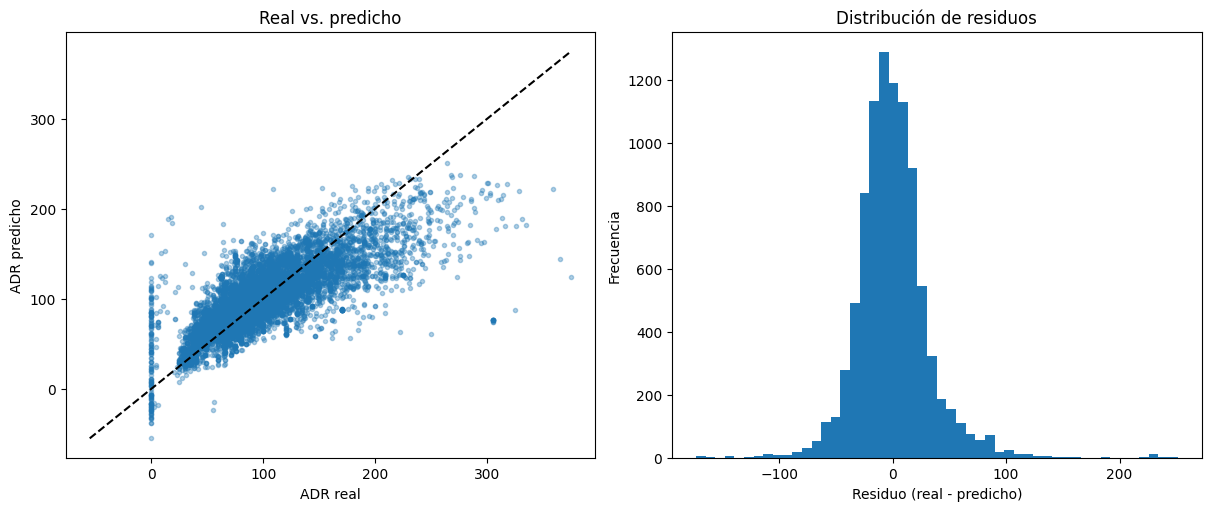

random_forest_regressor CV: {'cv_rmse_mean': 23.432935687841546, 'cv_rmse_std': 0.18582494798459545, 'cv_mae_mean': 15.393483970672778, 'cv_mae_std': 0.10581235519732957, 'cv_r2_mean': 0.763269190950484, 'cv_r2_std': 0.001086991270512333}
Validation: {'mae': 15.089119633864417, 'rmse': 23.541186897771883, 'r2': 0.7706289983687458}


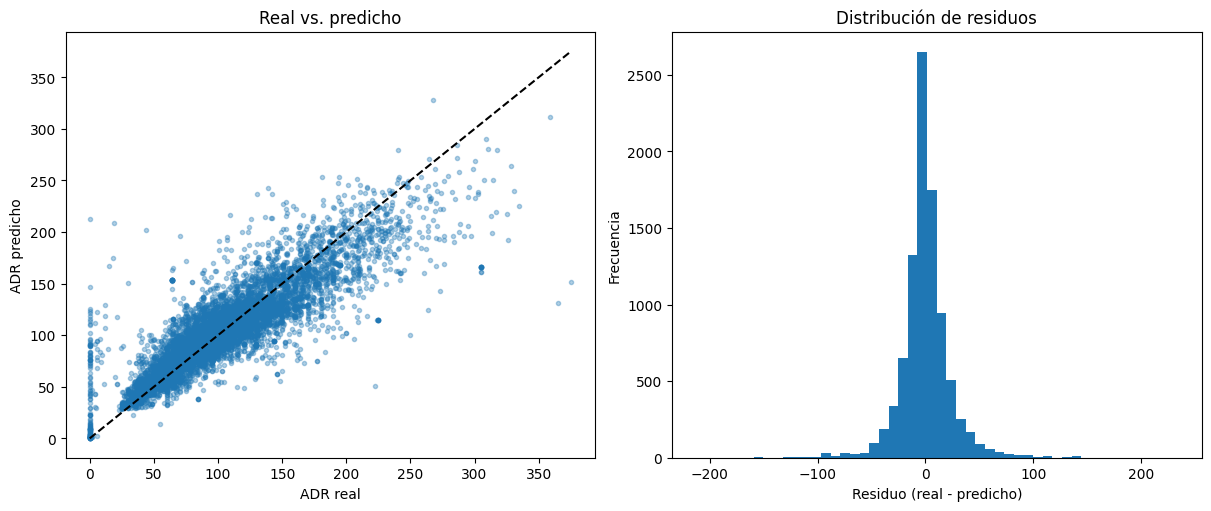

MODELOS DE CLASIFICACIÓN — Train/CV/Validation
random_forest_classifier CV: {'cv_roc_auc_mean': 0.8233908318793959, 'cv_roc_auc_std': 0.0059583645722583066, 'cv_f1_mean': 0.5857033103183542, 'cv_f1_std': 0.013835811185524344, 'cv_precision_mean': 0.8572718212007159, 'cv_precision_std': 0.0225287318594321, 'cv_recall_mean': 0.4451410976946957, 'cv_recall_std': 0.015762163171145132, 'cv_accuracy_mean': 0.7657353056277371, 'cv_accuracy_std': 0.0022287487467556088}
Validation: {'threshold': 0.5, 'accuracy': 0.7553471425679779, 'precision': 0.8665893271461717, 'recall': 0.4058312205722564, 'f1': 0.5527873704982733, 'roc_auc': 0.8117173204161523, 'confusion_matrix': [[8954, 345], [3281, 2241]]}


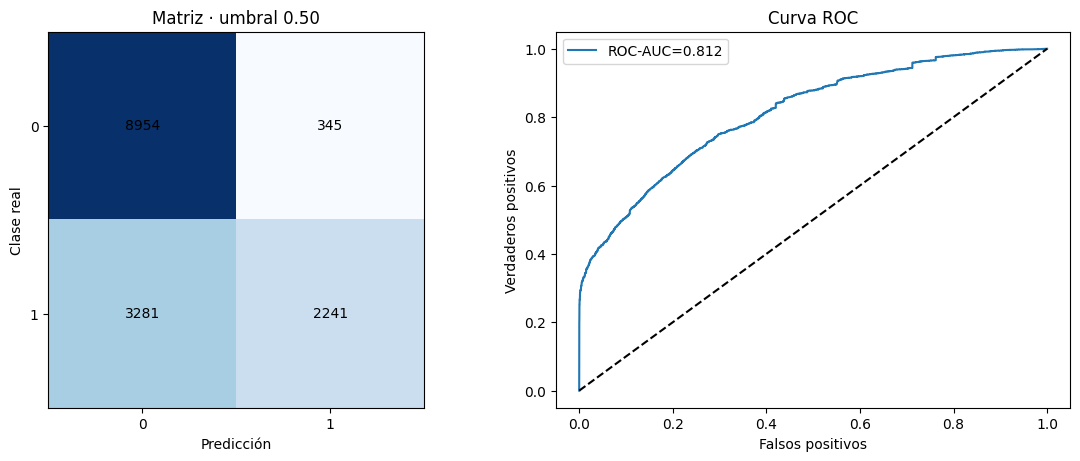

xgboost_classifier CV: {'cv_roc_auc_mean': 0.8228982708733596, 'cv_roc_auc_std': 0.001193688304781255, 'cv_f1_mean': 0.6003361180627665, 'cv_f1_std': 0.007477150327840971, 'cv_precision_mean': 0.7983267129745645, 'cv_precision_std': 0.01763073530392072, 'cv_recall_mean': 0.48138456026661175, 'cv_recall_std': 0.012522845604997461, 'cv_accuracy_mean': 0.7614483701973208, 'cv_accuracy_std': 0.0026943884317840333}
Validation: {'threshold': 0.5, 'accuracy': 0.7552796707374672, 'precision': 0.8063368897510508, 'recall': 0.4516479536399855, 'f1': 0.5789901334881021, 'roc_auc': 0.8075312277272048, 'confusion_matrix': [[8700, 599], [3028, 2494]]}


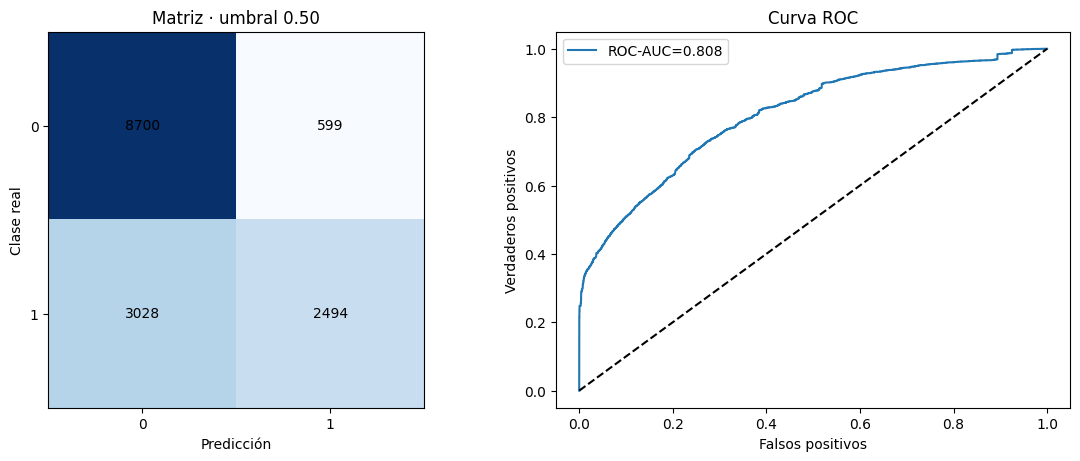

In [15]:
RESULTADOS_REGRESION = {}
RESULTADOS_CLASIFICACION = {}
if RUN_COSTLY_TRAINING:
    assert_environment_ready_for_training()
    RESULTADOS_REGRESION = run_regression_searches()
    RESULTADOS_CLASIFICACION = run_classification_searches()
    print('MODELOS DE REGRESIÓN — Train/CV/Validation')
    for nombre, salida in RESULTADOS_REGRESION.items():
        print(nombre, 'CV:', {k: v for k, v in salida['summary'].items() if k.startswith('cv_')})
        print('Validation:', salida['summary'].get('validation'))
        display(plot_regression_diagnostics(
            salida['estimator'], datasets['regression']['validation']))
        plt.close('all')
    print('MODELOS DE CLASIFICACIÓN — Train/CV/Validation')
    for nombre, salida in RESULTADOS_CLASIFICACION.items():
        print(nombre, 'CV:', {k: v for k, v in salida['summary'].items() if k.startswith('cv_')})
        print('Validation:', salida['summary'].get('validation'))
        display(plot_classification_diagnostics(
            salida['estimator'], datasets['classification']['validation']))
        plt.close('all')
else:
    print('Modelos supervisados pendientes: active RUN_COSTLY_TRAINING=True cuando esté autorizado.')


### Tarifa diaria media y errores de estimación

En las 9.299 reservas de validación que se mantuvieron, las predicciones de Random Forest se desviaron de la tarifa observada en 15,09 unidades monetarias por noche, en promedio absoluto. Con ElasticNet la desviación fue de 22,35. Random Forest también redujo el RMSE de 31,41 a 23,54 y elevó el R² de 0,592 a 0,771. La ventaja apareció también en la validación cruzada, con un RMSE medio de 23,43 para el bosque y de 30,86 para ElasticNet.

En los gráficos de tarifa real frente a predicha, los puntos cercanos a la diagonal representan estimaciones acertadas. En la parte alta del eje de tarifa real se observan reservas por debajo de esa línea, especialmente con ElasticNet: el modelo les asignó una tarifa inferior a la observada. El histograma de Random Forest concentra más errores cerca de cero, aunque todavía tiene una cola de residuos positivos. El bosque mejora la estimación para el conjunto de reservas, pero algunas noches de tarifa alta siguen siendo difíciles de valorar.

### Cancelaciones, falsas alertas y curvas ROC

Random Forest. Con un umbral de 0,50, el modelo detectó 2.241 de las 5.522 reservas que se cancelaron y dejó pasar 3.281. De las 9.299 reservas que se mantuvieron, clasificó correctamente 8.954 y generó 345 falsas alertas. Esto explica la diferencia entre su precisión y su sensibilidad. El 86,7 % de sus alertas correspondió a cancelaciones reales, pero solo logró detectar el 40,6 % del total de cancelaciones.

XGBoost. Con el mismo umbral, detectó 2.494 cancelaciones y dejó pasar 3.028. Clasificó correctamente 8.700 reservas que se mantuvieron y generó 599 falsas alertas. Frente a Random Forest, identificó 253 cancelaciones adicionales a cambio de 254 falsas alertas más. Su sensibilidad aumentó al 45,2 % y su precisión bajó al 80,6 %. Aunque ambos modelos alcanzaron una exactitud cercana al 75,5 %, sus errores tienen consecuencias distintas para el hotel.

Curvas ROC. Las dos curvas se sitúan por encima de la diagonal de referencia, lo que indica que ambos modelos distinguen las reservas canceladas de las que se mantuvieron mejor que una clasificación al azar. Random Forest obtuvo un AUC de 0,812 y XGBoost de 0,808. La diferencia observada es pequeña. Random Forest presentó una ligera ventaja al ordenar las reservas por riesgo considerando todos los umbrales, mientras que XGBoost detectó más cancelaciones en el umbral específico de 0,50.

En pocas palabras, si el hotel dispone de poco personal para revisar alertas, Random Forest ofrece mayor precisión. Si la prioridad es identificar más reservas con riesgo de cancelación y se puede asumir una mayor carga de revisión, XGBoost ofrece mayor sensibilidad. En el conjunto de validación, ambos modelos dejaron sin detectar más de la mitad de las cancelaciones reales con el umbral evaluado.

## 15. Clustering real: K-Means, codo, silueta, DBSCAN y perfiles

K-Means se ajusta en Train. Para DBSCAN se usa primero una muestra reproducible de 5.000 filas para seleccionar parámetros y controlar el consumo. **No se presenta la muestra como una segmentación de toda la base.** Si no existe una configuración DBSCAN aceptable según cobertura, ruido y silueta, se informa esa limitación sin inventar segmentos. El ajuste completo de DBSCAN queda sujeto a su propia autorización (`ALLOW_FULL_DBSCAN`).


k,inertia,inertia_std,silhouette,stability_ari_mean,stability_ari_min,iterations_mean
i64,f64,f64,f64,f64,f64,f64
2,543623.4375,0.0,0.541465,1.0,1.0,3.666667
3,472727.364583,2574.561059,0.545978,0.32701,-0.009485,7.333333
4,401276.864583,4055.608298,0.552237,0.511595,0.269557,11.0
5,335297.854167,4457.035311,0.325001,0.982195,0.975576,15.666667
6,279843.614583,19.196224,0.333998,0.992356,0.988544,13.333333
7,239106.333333,21.151185,0.369727,0.993542,0.990526,12.333333
8,202309.807292,11.568202,0.395899,0.996607,0.995228,9.333333
9,183451.489583,1.31846,0.397844,0.99938,0.99907,13.0
10,162738.755208,3.182194,0.409772,0.998268,0.997655,10.333333


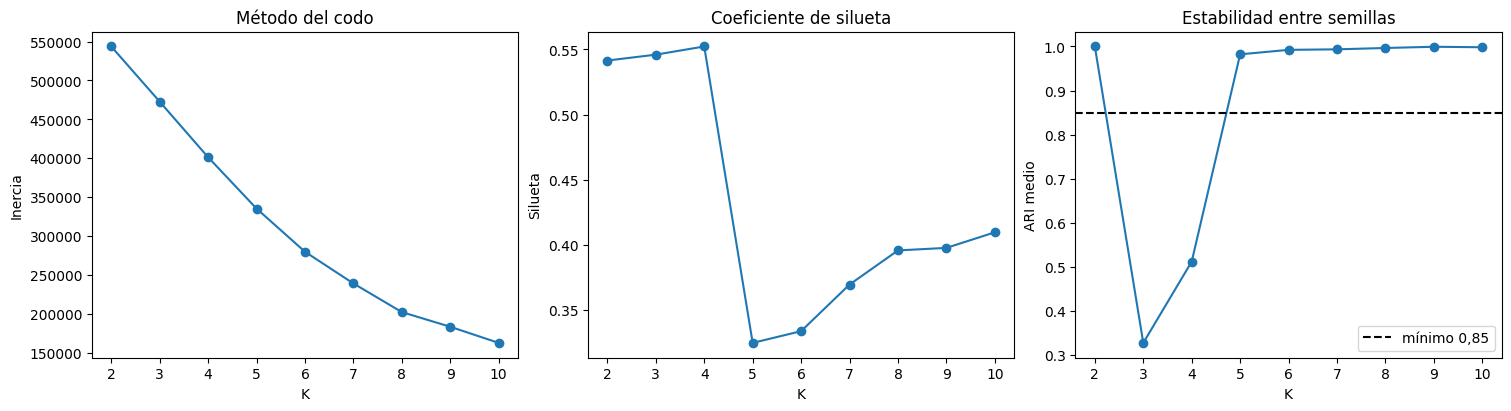

Selección K-Means: {'selected_k': None, 'elbow_k': 6, 'max_silhouette': 0.5522369146347046, 'silhouette_tolerance': 0.02, 'minimum_stability': 0.85, 'decision': 'manual_review_required_no_k_met_all_criteria'}
La regla no encontró K defendible. Revisar el codo y la silueta; no forzar selección.


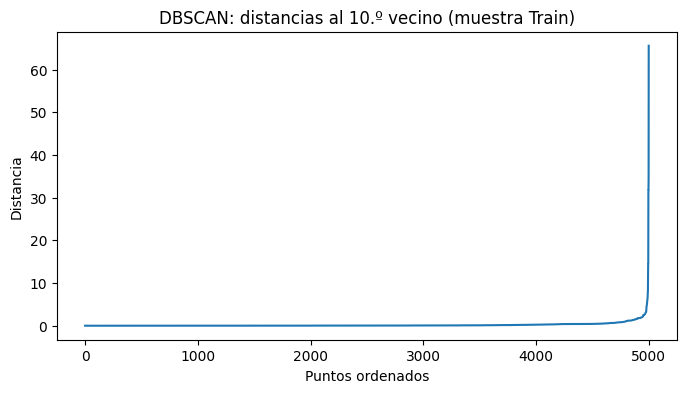

Valores eps candidatos: [0.394142, 0.425026, 0.800617, 1.438558]


eps,min_samples,clusters,coverage,noise_fraction,silhouette_assigned,sample_size,sample_hash,worst_case_pairwise_gb
f64,i64,i64,f64,f64,f64,i64,str,f64
0.394142,5,31,0.921,0.079,0.004129,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
0.425026,5,24,0.9536,0.0464,0.039802,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
0.800617,5,12,0.9746,0.0254,0.313983,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
1.438558,5,11,0.9904,0.0096,0.34362,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
0.394142,10,15,0.878,0.122,0.226413,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
…,…,…,…,…,…,…,…,…
1.438558,10,7,0.9816,0.0184,0.344595,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
0.394142,20,11,0.8042,0.1958,0.251983,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265
0.425026,20,10,0.8798,0.1202,0.246664,5000,"""cb863a30c05009af37d202a4ac2eb4…",0.186265


Selección DBSCAN piloto: {'selected': {'eps': 1.438558, 'min_samples': 20}, 'decision': 'selected_on_train_screening', 'criteria': {'minimum_coverage': 0.5, 'maximum_noise': 0.5, 'maximum_clusters': 20}, 'sample_hash': 'cb863a30c05009af37d202a4ac2eb49ccf0a9ba1f9af7230367e49912fb89c01'}
PERFILES DBSCAN (muestra de 5.000 filas de Train):


cluster,rows,lead_time__mean,lead_time__median,adults__mean,adults__median,children__mean,children__median,babies__mean,babies__median,total_nights__mean,total_nights__median,previous_cancellations__mean,previous_cancellations__median,previous_bookings_not_canceled__mean,previous_bookings_not_canceled__median
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-1,149,79.422819,35.0,1.899329,2.0,0.604027,0.0,0.248322,0.0,5.342282,3.0,0.932886,0.0,2.630872,0.0
0,142,83.957746,66.5,2.0,2.0,2.0,2.0,0.0,0.0,3.859155,3.0,0.007042,0.0,0.0,0.0
1,3409,119.629217,86.0,2.0,2.0,0.0,0.0,0.0,0.0,3.523614,3.0,0.062482,0.0,0.016134,0.0
2,903,64.988926,28.0,1.0,1.0,0.0,0.0,0.0,0.0,2.48948,2.0,0.053156,0.0,0.266888,0.0
3,230,104.613043,100.5,3.0,3.0,0.0,0.0,0.0,0.0,3.778261,3.0,0.0,0.0,0.0,0.0
4,167,90.610778,60.0,2.0,2.0,1.0,1.0,0.0,0.0,3.952096,4.0,0.0,0.0,0.017964,0.0


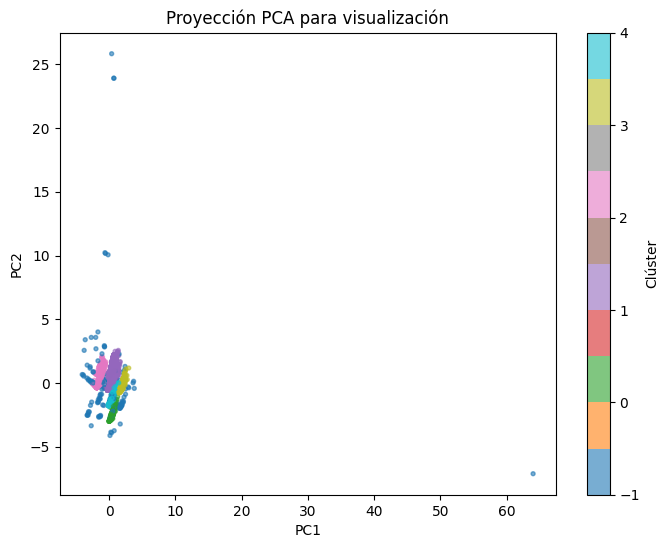

In [16]:
RESULTADOS_CLUSTERING = {}
if RUN_COSTLY_TRAINING:
    km_tabla, km_modelos, km_pre, km_frame, km_X = run_kmeans_analysis()
    display(km_tabla)
    display(plot_kmeans_diagnostics(km_tabla))
    plt.close('all')
    decision_k = select_kmeans_k(km_tabla)
    print('Selección K-Means:', decision_k)
    RESULTADOS_CLUSTERING['kmeans'] = {'tabla': km_tabla, 'seleccion': decision_k}
    if decision_k['selected_k'] is not None:
        k_elegido = decision_k['selected_k']
        km_mejor = km_modelos[k_elegido]
        perfil_km = cluster_profile(km_frame, km_mejor.labels_)
        print('PERFILES K-MEANS:')
        display(perfil_km)
        validacion_km = kmeans_validation_analysis(km_mejor, km_pre)
        print('Silueta K-Means en Validation:', validacion_km['silhouette'])
        display(plot_cluster_projection(km_X, km_mejor.labels_))
        plt.close('all')
    else:
        print('La regla no encontró K defendible. Revisar el codo y la silueta; no forzar selección.')

    # El gráfico de k-distancias y eps se deriva únicamente de Train.
    diagnostico_distancias = k_distance_diagnostic(km_X, min_samples=10, sample_size=5000)
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(diagnostico_distancias['distances'])
    ax.set(title='DBSCAN: distancias al 10.º vecino (muestra Train)',
           xlabel='Puntos ordenados', ylabel='Distancia')
    display(fig)
    plt.close(fig)
    eps_candidatos = propose_dbscan_eps(diagnostico_distancias['distances'])
    print('Valores eps candidatos:', eps_candidatos)
    if eps_candidatos:
        db_tabla, db_etiquetas, db_indices, db_pre, db_frame, db_X = run_dbscan_screening(
            eps_candidatos, min_samples_values=(5, 10, 20), sample_size=5000
        )
        display(db_tabla)
        db_decision = select_dbscan_configuration(db_tabla)
        print('Selección DBSCAN piloto:', db_decision)
        RESULTADOS_CLUSTERING['dbscan'] = {'tabla': db_tabla, 'seleccion': db_decision}
        if db_decision['selected'] is not None:
            configuracion = db_decision['selected']
            clave = (configuracion['eps'], configuracion['min_samples'])
            labels_piloto = db_etiquetas[clave]
            print('PERFILES DBSCAN (muestra de 5.000 filas de Train):')
            display(cluster_profile(db_frame[db_indices], labels_piloto))
            display(plot_cluster_projection(db_X[db_indices], labels_piloto))
            plt.close('all')
            if ALLOW_FULL_DBSCAN:
                modelo_db, etiquetas_db, metricas_db, _, df_db, X_db = fit_final_dbscan(**configuracion)
                print('DBSCAN TRAIN COMPLETO:', metricas_db)
                display(cluster_profile(df_db, etiquetas_db))
        else:
            print('DBSCAN no alcanzó los criterios en la muestra; documentar la limitación.')
else:
    print('Clustering pendiente: no se utilizaron los datos Test.')


### Interpretación de K-Means
El método del codo señaló K = 6 como el punto a partir del cual añadir más grupos produjo reducciones menores en la variación interna de las reservas. El coeficiente de silueta favoreció K = 4 (0,552), pero al repetir el ajuste con distintas semillas cambió la composición de esos cuatro grupos (ARI medio de 0,512). Con seis grupos, las asignaciones fueron más estables (ARI medio de 0,992). Por esta razón se eligió K = 6 para describir los perfiles de reserva. Su silueta fue de 0,334 en entrenamiento y 0,341 en validación, lo que indica una separación similar en ambas particiones, aunque existe solapamiento entre los grupos.

La regla automática dejó la selección abierta porque ningún K cumplió simultáneamente los criterios de silueta y estabilidad. La elección de seis grupos se tomó al revisar las tres curvas.

### Interpretación de DBSCAN y de la proyección PCA
La curva de distancia al décimo vecino sube con rapidez en su extremo derecho. Esas reservas necesitaron un radio mayor para encontrar vecinos. La tabla muestra el efecto del radio: con `min_samples = 20`, pasar de `eps = 0,394142` a `eps = 1,438558` redujo los grupos de once a cinco y los puntos sin asignar del 19,58 % al 2,98 %.

En la muestra de 5.000 reservas, DBSCAN identificó cinco grupos y asignó la etiqueta −1 a 149 reservas (2,98 %) que quedaron fuera de las agrupaciones. La composición de los huéspedes y la anticipación permiten interpretar los perfiles. El clúster 1, el más numeroso, reunió 3.409 reservas (68,18 %) de dos adultos sin niños, con medianas de 86 días de anticipación y tres noches. El clúster 2 reunió 903 reservas de un adulto sin niños, con medianas de 28 días de anticipación y dos noches. En esta muestra, las reservas individuales tendieron a realizarse más cerca de la llegada y a tener estancias más cortas que las del grupo principal.

Los grupos restantes distinguen composiciones menos frecuentes. El clúster 0 reunió 142 reservas de dos adultos con dos niños. El clúster 3 agrupó 230 reservas de tres adultos sin niños y el clúster 4, 167 reservas de dos adultos con un niño. Estos perfiles permiten describir qué tipos de reserva aparecen en la muestra y con cuánta anticipación se reciben.

En la proyección PCA, varios colores se superponen en la zona de mayor concentración y algunos puntos aparecen alejados en el eje vertical. Los dos ejes resumen las variables originales, por lo que reservas que se ven próximas en el gráfico pueden diferir en características que la proyección representa solo parcialmente. La silueta de 0,349, calculada sobre las reservas asignadas, es coherente con esa separación parcial. La tabla permite interpretar las diferencias concretas entre los grupos, mientras que el gráfico muestra cuánto se superponen al representarlos en dos dimensiones.

K seleccionado: 6
Silueta K-Means en Validation: 0.340896338224411


cluster,rows,lead_time__mean,lead_time__median,adults__mean,adults__median,children__mean,children__median,babies__mean,babies__median,total_nights__mean,total_nights__median,previous_cancellations__mean,previous_cancellations__median,previous_bookings_not_canceled__mean,previous_bookings_not_canceled__median
i32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,54492,47.245082,34.0,1.773398,2.0,0.0,0.0,0.0,0.0,2.708544,2.0,0.036336,0.0,0.122201,0.0
1,6274,88.781798,64.0,1.951068,2.0,1.455371,1.0,0.0,0.0,3.889066,3.0,0.007172,0.0,0.014026,0.0
2,695,78.18705,51.0,1.995683,2.0,0.246043,0.0,1.038849,1.0,4.141007,4.0,0.007194,0.0,0.015827,0.0
3,222,19.351351,4.0,1.126126,1.0,0.004505,0.0,0.0,0.0,1.918919,2.0,2.463964,1.0,25.040541,20.0
4,27181,226.207056,211.0,2.012435,2.0,0.000773,0.0,0.0,0.0,4.79688,4.0,0.106655,0.0,0.009345,0.0
5,59,248.59322,244.0,2.0,2.0,0.0,0.0,0.0,0.0,4.101695,2.0,23.338983,24.0,0.118644,0.0


cluster,len
i32,u32
0,9372
1,1032
2,103
3,37
4,4239
5,38


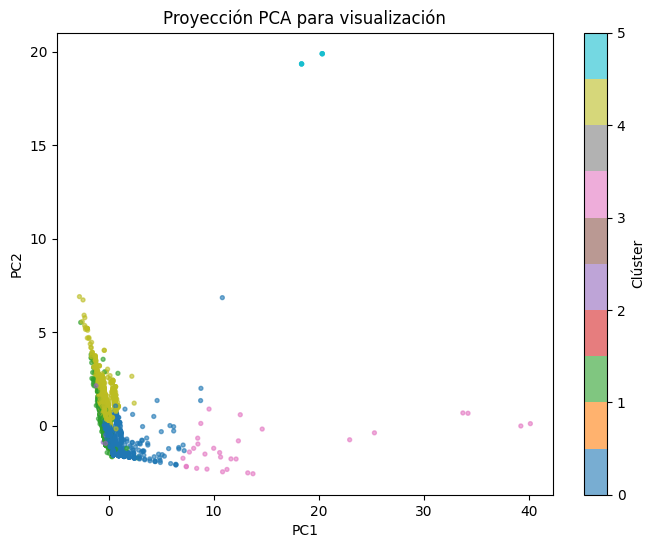

In [17]:
# K=6 se fija por la decisión metodológica documentada en la celda anterior.
K_ELEGIDO_AUDITADO = 6
assert K_ELEGIDO_AUDITADO in km_modelos
km_seleccionado = km_modelos[K_ELEGIDO_AUDITADO]
perfil_kmeans_seleccionado = cluster_profile(km_frame, km_seleccionado.labels_)
validacion_kmeans_seleccionado = kmeans_validation_analysis(km_seleccionado, km_pre)
print('K seleccionado:', K_ELEGIDO_AUDITADO)
print('Silueta K-Means en Validation:', validacion_kmeans_seleccionado['silhouette'])
display(perfil_kmeans_seleccionado)
display(validacion_kmeans_seleccionado['counts'])
display(plot_cluster_projection(km_X, km_seleccionado.labels_))
plt.close('all')


### Qué distingue a los seis perfiles de K-Means

La anticipación de la reserva distingue a los dos grupos más numerosos. El clúster 0 reunió 54.492 reservas con una mediana de 34 días de anticipación, mientras que el clúster 4 agrupó 27.181 reservas con una mediana de 211 días. Juntos representan cerca del 92 % de las reservas de entrenamiento. Para el hotel, esta diferencia permite distinguir la demanda que se registra con aproximadamente un mes de anticipación de aquella que ya es visible unos siete meses antes de la llegada. Los dos grupos más pequeños, con 222 y 59 reservas, describen patrones poco frecuentes y requieren cautela al extraer conclusiones comerciales.

La composición de los huéspedes aporta otra diferencia. En el clúster 1 (6.274 reservas) la mediana fue de un niño y tres noches. En el clúster 2 (695 reservas) fue de un bebé y cuatro noches. Los dos segmentos más pequeños se distinguen por el historial: en el clúster 3 la mediana fue de 20 reservas anteriores que se mantuvieron y cuatro días de anticipación; en el clúster 5 fue de 24 cancelaciones anteriores y 244 días de anticipación.

Al aplicar los centros aprendidos a las 14.821 reservas de validación, 9.372 quedaron en el clúster 0 y 4.239 en el clúster 4. En conjunto representan el 91,8 %, una concentración muy parecida a la de entrenamiento. En la proyección PCA se observan zonas con varios colores y puntos alejados de la concentración principal. Las medianas de la tabla permiten distinguir perfiles que, al reducir los datos a dos ejes, aparecen próximos. Los números de grupo corresponden a cada algoritmo por separado.

## 16. MLP real con PyTorch: comparación, pérdida y sobreajuste

El MLP se entrena con Train y early stopping según Validation. El mismo umbral primario 0,5 permite compararlo con los clasificadores clásicos. Se conservan curvas de pérdida, arquitectura, época de mejor validación y checkpoints.


Comparación de arquitecturas MLP (Validation):


candidate_id,threshold,accuracy,precision,recall,f1,roc_auc,confusion_matrix,validation_loss,parameter_count,configuration_hash
str,f64,f64,f64,f64,f64,f64,list[list[i64]],f64,i64,str
"""balanced""",0.5,0.758991,0.815738,0.456175,0.585134,0.810018,"[[8730, 569], [3003, 2519]]",0.481159,15361,"""c13e3e1373148385cee45bbe448e1d…"
"""small""",0.5,0.756697,0.775922,0.487867,0.599066,0.804441,"[[8521, 778], [2828, 2694]]",0.484237,5633,"""fed878fe16fe9f81d8c4fd0b104ab9…"
"""regularized""",0.5,0.756157,0.836864,0.429192,0.567393,0.804342,"[[8837, 462], [3152, 2370]]",0.486306,17409,"""f615534c0184108001a1e781c74ddd…"


MLP seleccionado: balanced
small época óptima: 15


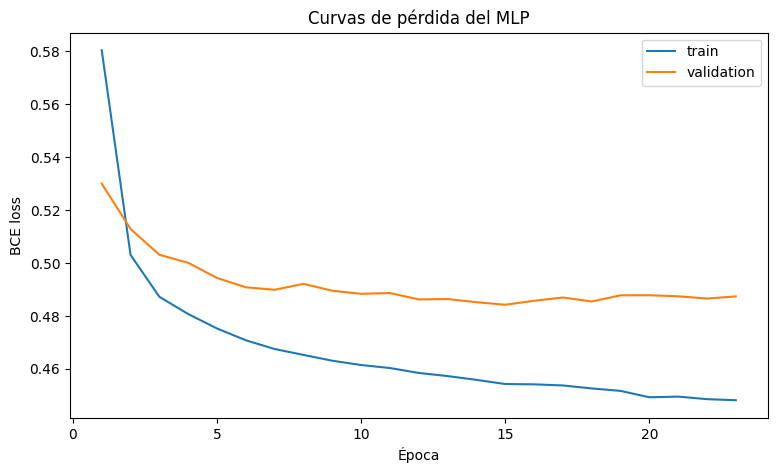

balanced época óptima: 13


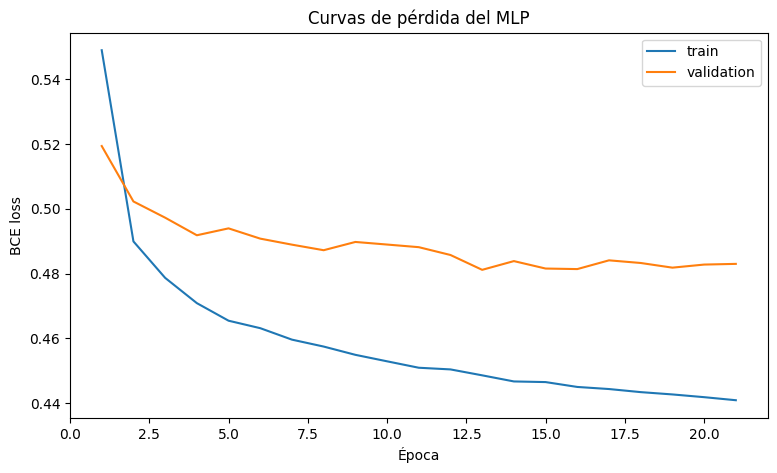

regularized época óptima: 15


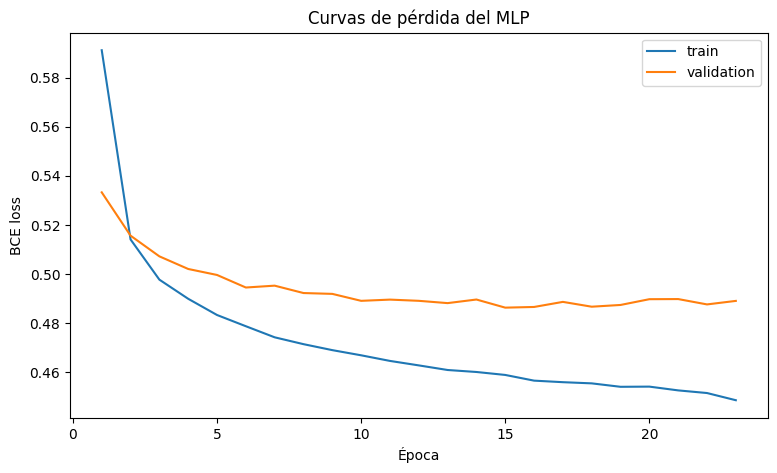

In [18]:
RESULTADOS_MLP = {}
if RUN_COSTLY_TRAINING:
    salidas_mlp, tabla_mlp, mlp_elegido = run_mlp_candidates()
    RESULTADOS_MLP = salidas_mlp
    print('Comparación de arquitecturas MLP (Validation):')
    display(tabla_mlp)
    print('MLP seleccionado:', mlp_elegido)
    for nombre, salida in salidas_mlp.items():
        print(nombre, 'época óptima:', salida['metadata']['best_epoch'])
        display(plot_mlp_losses(salida['history']))
        plt.close('all')
else:
    print('MLP pendiente; la mera definición de PyTorch no acredita entrenamiento.')


### Qué aprendieron las tres redes y cuándo dejaron de mejorar

La arquitectura `balanced` (128 y 64 neuronas en sus capas ocultas) obtuvo el mayor AUC de las tres redes, 0,810. En su curva, la pérdida de validación alcanzó el mínimo de 0,4812 en la época 13. En la última época registrada, la pérdida de entrenamiento era de 0,4409 y la de validación de 0,4830. Seguir ajustando los pesos redujo el error sobre las reservas conocidas, pero la mejora en validación ya se había agotado. Por eso se recuperaron los pesos de la época 13. Las redes `small` y `regularized` alcanzaron sus mínimos en la época 15, con pérdidas de 0,4842 y 0,4863, respectivamente.

Con el umbral de 0,50, `small` detectó 2.694 cancelaciones y generó 778 falsas alertas. `balanced` detectó 2.519 y generó 569 falsas alertas. Elegir la red pequeña habría permitido identificar 175 cancelaciones más a cambio de revisar 209 alertas falsas adicionales. `regularized` produjo la mayor precisión de las tres (83,7 %), aunque detectó solo el 42,9 % de las cancelaciones. La elección de `balanced` responde al objetivo de ordenar las reservas por riesgo. Si el hotel priorizara cuántas cancelaciones alcanza a detectar con ese umbral, `small` obtuvo la mayor sensibilidad (48,8 %) y el mayor F1 (0,599).

## 17. Interpretabilidad y tabla comparativa de modelos

Se calcula importancia por permutación sobre Validation, para evitar el sesgo de utilizar Test. La importancia intrínseca complementa los resultados; SHAP es opcional cuando su coste computacional sea viable. Interpretación predictiva **no equivale a causalidad**.


COMPARACIÓN CON BASELINES DE FASE 2 — SOLO VALIDATION:


phase,task,model,split,accuracy,precision,recall,f1,roc_auc,mae,rmse,r2,threshold
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Fase 2""","""classification""","""dummy""","""validation""",0.627421,0.0,0.0,0.0,0.5,null,null,null,null
"""Fase 2""","""classification""","""logistic""","""validation""",0.73072,0.764239,0.400942,0.525953,0.754028,null,null,null,null
"""Fase 2""","""regression""","""dummy""","""validation""",null,null,null,null,null,37.392645,49.15537,-0.000055,null
"""Fase 2""","""regression""","""linear""","""validation""",null,null,null,null,null,22.346944,31.39346,0.592094,null
"""Fase 3""","""regression""","""elastic_net""","""validation""",null,null,null,null,null,22.350468,31.405283,0.591787,null
…,…,…,…,…,…,…,…,…,…,…,…,…
"""Fase 3""","""classification""","""random_forest_classifier""","""validation""",0.755347,0.866589,0.405831,0.552787,0.811717,null,null,null,0.5
"""Fase 3""","""classification""","""xgboost_classifier""","""validation""",0.75528,0.806337,0.451648,0.57899,0.807531,null,null,null,0.5
"""Fase 3""","""classification""","""MLP_small""","""validation""",0.756697,0.775922,0.487867,0.599066,0.804441,null,null,null,0.5


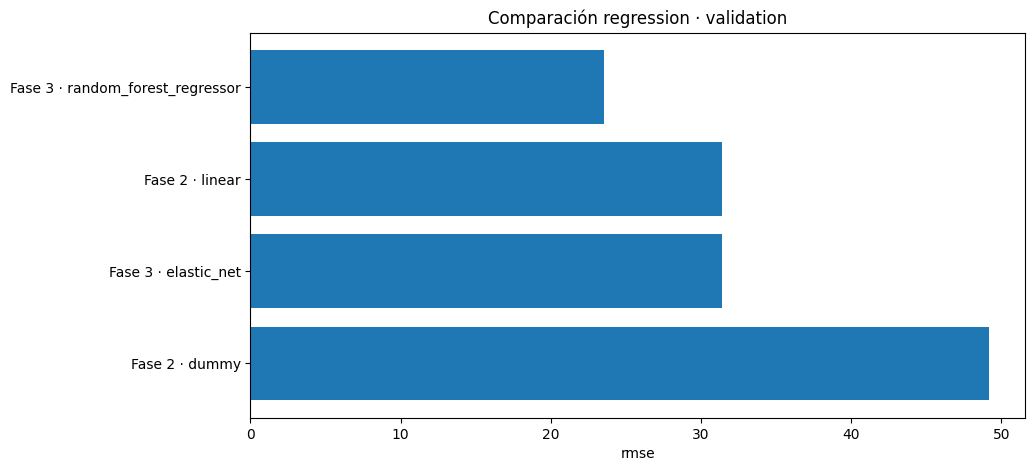

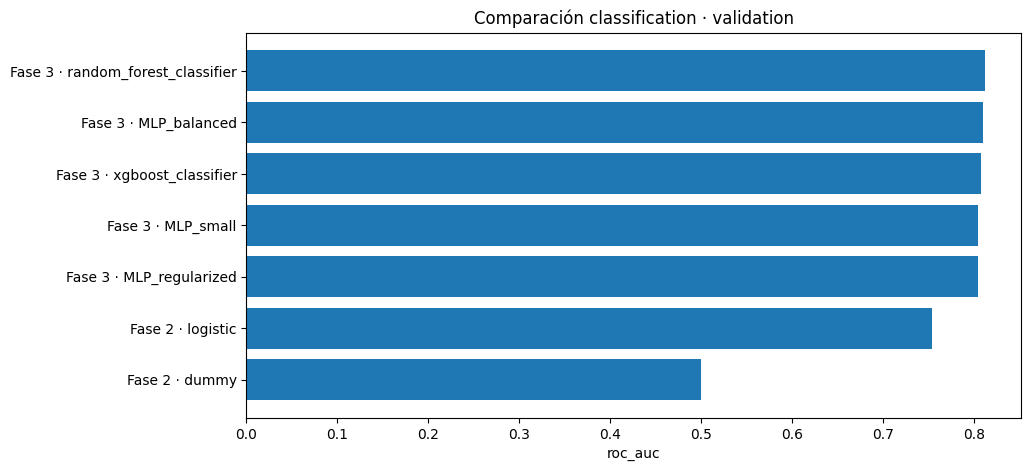

Importancia por permutación regression, modelo random_forest_regressor:


variable,importance_mean,importance_std
str,f64,f64
"""arrival_date_month""",20.184883,1.066821
"""hotel""",14.306632,0.958164
"""market_segment""",8.433741,0.250001
"""reserved_room_type""",7.475601,0.561548
"""meal""",3.979651,0.777521
…,…,…
"""distribution_channel""",0.058935,0.04181
"""previous_bookings_not_canceled""",0.028586,0.013505
"""is_repeated_guest""",0.013132,0.00453


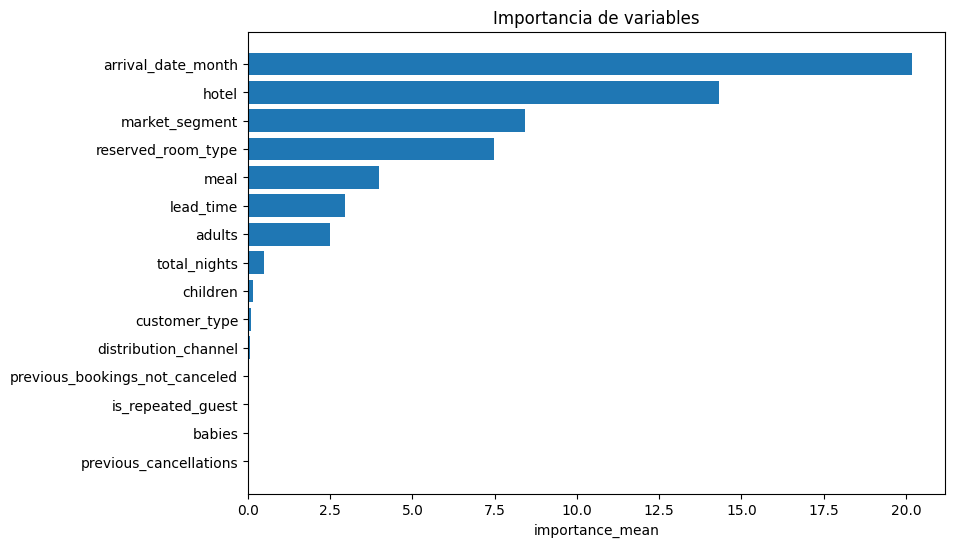

Importancia agregada por variable original:


source_variable,absolute_importance_sum,signed_sum,transformed_columns
str,f64,f64,u32
"""arrival_date_month""",0.315854,0.315854,12
"""reserved_room_type""",0.181534,0.181534,9
"""hotel""",0.12736,0.12736,2
"""market_segment""",0.106975,0.106975,7
"""lead_time""",0.062195,0.062195,1
…,…,…,…
"""customer_type""",0.010154,0.010154,4
"""previous_bookings_not_canceled""",0.001705,0.001705,1
"""is_repeated_guest""",0.001462,0.001462,2


Importancia por permutación classification, modelo random_forest_classifier:


variable,importance_mean,importance_std
str,f64,f64
"""customer_type""",0.092617,0.002011
"""lead_time""",0.089417,0.00254
"""market_segment""",0.060914,0.007033
"""previous_cancellations""",0.056461,0.004804
"""hotel""",0.019534,0.004955
…,…,…
"""arrival_date_month""",0.006829,0.001788
"""adults""",0.005979,0.002797
"""is_repeated_guest""",0.004462,0.000811


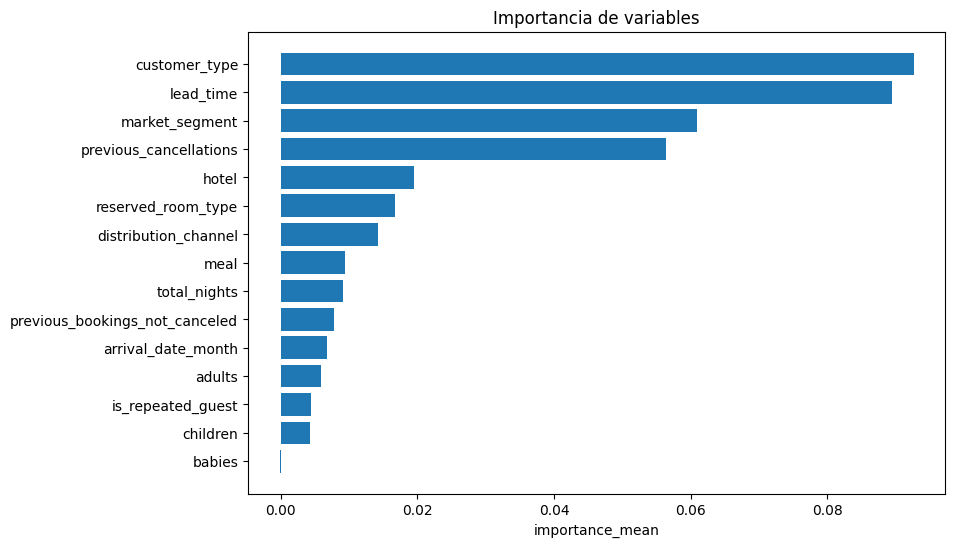

Importancia agregada por variable original:


source_variable,absolute_importance_sum,signed_sum,transformed_columns
str,f64,f64,u32
"""lead_time""",0.229979,0.229979,1
"""market_segment""",0.198135,0.198135,8
"""customer_type""",0.157551,0.157551,4
"""previous_cancellations""",0.145286,0.145286,1
"""arrival_date_month""",0.055233,0.055233,12
…,…,…,…
"""adults""",0.014676,0.014676,1
"""is_repeated_guest""",0.010184,0.010184,2
"""previous_bookings_not_canceled""",0.010171,0.010171,1


SHAP: función tree_shap_validation(modelo, task) disponible para un árbol elegido.
Se omite SHAP automático para evitar agotar RAM: ya existe importancia por permutación.


In [19]:
TABLA_COMPARACION_FASE3 = None
if RUN_COSTLY_TRAINING:
    # Se conservan CV y Validation de cada modelo; nunca Test.
    avances = []
    for task, outputs in [('regression', RESULTADOS_REGRESION),
                          ('classification', RESULTADOS_CLASIFICACION)]:
        for nombre, salida in outputs.items():
            modelo = salida['estimator']
            metricas = salida['summary']['validation']
            fila = {'phase': 'Fase 3', 'task': task, 'model': nombre,
                    'split': 'validation',
                    **{k: v for k, v in metricas.items()
                       if isinstance(v, (int, float)) and not isinstance(v, bool)}}
            avances.append(fila)
    if RESULTADOS_MLP:
        for nombre, salida in RESULTADOS_MLP.items():
            avances.append({'phase': 'Fase 3', 'task': 'classification',
                            'model': 'MLP_' + nombre, 'split': 'validation',
                            **{k: v for k, v in salida['validation_metrics'].items()
                               if isinstance(v, (int, float)) and not isinstance(v, bool)}})
    # La tabla visible es una comparación informativa. Los artefactos de cada
    # búsqueda ya se guardaron con sus hashes en artifacts_phase3.
    avanzados = pl.DataFrame(avances)
    TABLA_COMPARACION_FASE3 = pl.concat(
        [phase2_baseline_table(), avanzados], how='diagonal_relaxed'
    )
    print('COMPARACIÓN CON BASELINES DE FASE 2 — SOLO VALIDATION:')
    display(TABLA_COMPARACION_FASE3)
    for task, metric in [('regression', 'rmse'), ('classification', 'roc_auc')]:
        display(plot_model_comparison(TABLA_COMPARACION_FASE3, task, metric))
        plt.close('all')
    for task, outputs, scoring in [
        ('regression', RESULTADOS_REGRESION, 'neg_root_mean_squared_error'),
        ('classification', RESULTADOS_CLASIFICACION, 'roc_auc')]:
        metric = 'rmse' if task == 'regression' else 'roc_auc'
        mejor = min(outputs, key=lambda nombre: outputs[nombre]['summary']['validation'][metric]) if task == 'regression' else max(
            outputs, key=lambda nombre: outputs[nombre]['summary']['validation'][metric])
        estimador = outputs[mejor]['estimator']
        print(f'Importancia por permutación {task}, modelo {mejor}:')
        tabla_importancia = permutation_importance_validation(estimador, task, scoring)
        display(tabla_importancia)
        display(plot_importance(tabla_importancia))
        plt.close('all')
        detalle, agregado = intrinsic_importance_table(estimador)
        print('Importancia agregada por variable original:')
        display(agregado.head(15))
    print('SHAP: función tree_shap_validation(modelo, task) disponible para un árbol elegido.')
    print('Se omite SHAP automático para evitar agotar RAM: ya existe importancia por permutación.')
else:
    print('Interpretabilidad y comparaciones esperan resultados reales de entrenamiento.')


### Cuánto aportaron los modelos frente a la Fase 2

En la gráfica de tarifas, una barra más corta indica menor RMSE. El error pasó de 49,16 con la predicción constante a 31,39 con la regresión lineal. ElasticNet quedó prácticamente en el mismo punto (31,41), mientras que Random Forest redujo el error a 23,54. La mejora del bosque sobre la regresión lineal fue del 25,0 % en esta partición.

En la gráfica de cancelaciones, una barra más larga indica mayor AUC. La referencia constante obtuvo 0,500 y la regresión logística alcanzó 0,754. Random Forest (0,812), el MLP `balanced` (0,810) y XGBoost (0,808) mejoraron la capacidad de ordenar reservas por riesgo. Entre esos tres modelos hay solo cuatro milésimas de diferencia en validación. Sus matrices de confusión muestran diferencias más relevantes para decidir cuántas alertas estaría dispuesto a revisar el hotel.

### Variables que más pesaron en la estimación de tarifas

Al mezclar al azar el mes de llegada entre las 800 reservas de la muestra de validación, el RMSE de Random Forest aumentó en promedio 20,18 unidades. Al mezclar el hotel aumentó 14,31, seguido del segmento de mercado (8,43) y del tipo de habitación reservada (7,48). El mes también ocupó el primer lugar en la importancia interna del bosque. El tipo de habitación pasó al segundo lugar con esa medida. Ambas lecturas indican que el modelo utiliza el calendario y las características de la reserva para estimar la tarifa. El aumento de 20,18 mide cuánto empeora la predicción al perder la información del mes, sin indicar cuánto cambia el precio de una noche entre meses.

### Variables que más pesaron en la clasificación de cancelaciones

En el bosque de clasificación, mezclar el tipo de cliente redujo el AUC en 0,093 y mezclar la anticipación de la reserva lo redujo en 0,089. Les siguieron el segmento de mercado (0,061) y las cancelaciones anteriores (0,056). La importancia interna también ubicó esas cuatro variables en los cuatro primeros lugares, aunque dio el primer puesto a la anticipación. Esto explica qué información utilizó el modelo para ordenar las reservas. Para saber si un plazo concreto de anticipación se asocia con mayor o menor riesgo haría falta examinar la dirección de esa relación.

## 18. Alcance de los resultados

Las reservas pertenecen a dos hoteles portugueses y al periodo 2015–2017. La clasificación usa la información disponible en la fotografía previa a la llegada. Usarla para emitir una alerta en el instante de la reserva requeriría comprobar qué variables ya se conocían en ese momento. La estimación de tarifas se limita a las reservas que se mantuvieron.

## 18.A. Lista de comprobación basada en evidencia

La tabla siguiente **no es una calificación del docente**. Diferencia claramente código definido de **resultados efectivamente calculados**. No se adjudica el 99 % sin evidencia experimental. Los cuatro bloques del checklist son: supervisado, clustering, MLP y optimización/interpretabilidad.


In [20]:
# Informe de cumplimiento verificable (sin consulta de Test).
from IPython.display import display

def crear_checklist_fase3() -> pl.DataFrame:
    """
    Construye una lista de chequeo con base en resultados ejecutados.

    Retorna
    -------
    pl.DataFrame
        Requisitos y evidencia de ejecución disponible en memoria.

    Notas
    -----
    Esta tabla no representa la calificación oficial de la universidad.
    """
    supervised = (
        len(RESULTADOS_REGRESION) >= 2 and len(RESULTADOS_CLASIFICACION) >= 2
    )
    clustering = (
        'kmeans' in RESULTADOS_CLUSTERING and
        'dbscan' in RESULTADOS_CLUSTERING and
        ('K_ELEGIDO_AUDITADO' in globals() and K_ELEGIDO_AUDITADO in km_modelos and 'validacion_kmeans_seleccionado' in globals())
    )
    mlp = bool(RESULTADOS_MLP) and all(
        bool(resultado.get('history') is not None and resultado['history'].height)
        for resultado in RESULTADOS_MLP.values()
    )
    interpretation = (
        supervised and TABLA_COMPARACION_FASE3 is not None and TABLA_COMPARACION_FASE3.height > 0
    )
    checks = [
        ('Regresión regularizada + ensamble y dos clasificadores', supervised,
         'Búsquedas entrenadas y evaluadas en Validation'),
        ('K-Means: codo/silueta y segundo algoritmo DBSCAN', clustering,
         'Resultados y selección documentada sobre Train'),
        ('MLP entrenado con PyTorch y curvas de pérdida', mlp,
         'Historial real de entrenamiento y validación'),
        ('Optimización CV, comparación e importancia de variables', interpretation,
         'CV y comparación calculadas; verificar gráficos de importancia'),
    ]
    return pl.DataFrame([
        {'criterio': nombre, 'evidencia_generada': evidencia,
         'interpretacion': texto}
        for nombre, evidencia, texto in checks
    ])

CHECKLIST_FASE3 = crear_checklist_fase3()
display(CHECKLIST_FASE3)
print('Esta comprobación es informativa; revise también las figuras y salidas reales.')

criterio,evidencia_generada,interpretacion
str,bool,str
"""Regresión regularizada + ensam…",true,"""Búsquedas entrenadas y evaluad…"
"""K-Means: codo/silueta y segund…",true,"""Resultados y selección documen…"
"""MLP entrenado con PyTorch y cu…",true,"""Historial real de entrenamient…"
"""Optimización CV, comparación e…",true,"""CV y comparación calculadas; v…"


Esta comprobación es informativa; revise también las figuras y salidas reales.


Los cuatro apartados del listado registraron evidencia. Esto confirma que las búsquedas, la segmentación, el entrenamiento de las redes y la comparación produjeron salidas en esta ejecución. La evaluación en Test sigue siendo una etapa aparte.

## 19. Congelación opcional del modelo definitivo y autorización de Test

La guía exige evaluar sobre datos no usados durante la selección. **Este paso no se ejecuta automáticamente.** Después de revisar la tabla de validación y la interpretación, decida si procede congelar la selección. El código registra modelos y parámetros en archivos inmutables para la futura evaluación final.

- `CONGELAR_MODELOS=False` inicialmente. Cambie a `True` **solo cuando haya revisado y aceptado los modelos elegidos a partir de Validation**.
- La selección de regresión usa RMSE mínimo en Validation.
- La selección de clasificación usa ROC-AUC máximo en Validation entre RF, XGBoost y MLP, con umbral primario 0,5.
- Esta congelación **no abre Test**. Mantenga `ALLOW_TEST_EVALUATION=False` hasta autorización separada.
- Si desea criterio distinto (por ejemplo F1 o coste de falsos negativos), modifique la selección antes de congelarla y documente la razón.


In [21]:
CONGELAR_MODELOS = False  # Debe activarse solo tras inspección humana de Validation.
if CONGELAR_MODELOS:
    if not RUN_COSTLY_TRAINING or ALLOW_TEST_EVALUATION:
        raise RuntimeError('Congele después de entrenar y antes de permitir Test.')
    if not RESULTADOS_REGRESION or not RESULTADOS_CLASIFICACION:
        raise RuntimeError('Faltan modelos supervisados evaluados en Validation.')
    mejores = {
        'regression': min(RESULTADOS_REGRESION, key=lambda k:
            RESULTADOS_REGRESION[k]['summary']['validation']['rmse']),
        'classification': max(RESULTADOS_CLASIFICACION, key=lambda k:
            RESULTADOS_CLASIFICACION[k]['summary']['validation']['roc_auc']),
    }
    # Si MLP logra mayor ROC-AUC sobre la MISMA partición, se considera ganador.
    if RESULTADOS_MLP:
        mejor_mlp = max(RESULTADOS_MLP, key=lambda k:
            RESULTADOS_MLP[k]['validation_metrics']['roc_auc'])
        if (RESULTADOS_MLP[mejor_mlp]['validation_metrics']['roc_auc'] >
            RESULTADOS_CLASIFICACION[mejores['classification']]['summary']['validation']['roc_auc']):
            mejores['classification'] = 'MLP_' + mejor_mlp
    print('Selección propuesta exclusivamente con Validation:', mejores)
    for tarea in ('regression', 'classification'):
        nombre = mejores[tarea]
        if nombre.startswith('MLP_'):
            item = RESULTADOS_MLP[nombre.removeprefix('MLP_')]
            directorio = item['run_directory']
            path = directorio / 'model_final.pt'
            auxiliar = {'preprocessor': directorio / 'preprocessor.joblib'}
            parametros = item['metadata']
            evidencia = item['validation_metrics']
            tipo = 'pytorch_mlp'
        else:
            item = (RESULTADOS_REGRESION if tarea == 'regression'
                    else RESULTADOS_CLASIFICACION)[nombre]
            coincidencias = []
            for resumen_path in (ARTIFACT_ROOT / nombre).glob('*/summary.json'):
                resumen = json.loads(resumen_path.read_text(encoding='utf-8'))
                if resumen.get('best_params') == item['summary'].get('best_params') and                    resumen.get('validation') == item['summary'].get('validation'):
                    coincidencias.append(resumen_path)
            if len(coincidencias) != 1:
                raise RuntimeError(f'No se identificó un artefacto único para {nombre}.')
            path = coincidencias[0].parent / 'model.joblib'
            auxiliar = None
            parametros = item['summary']['best_params']
            evidencia = item['summary']['validation']
            tipo = 'sklearn'
        congelado = register_final_selection(
            task=tarea, model_name=nombre, artifact_path=path,
            hyperparameters=parametros,
            validation_evidence=evidencia, threshold=(0.5 if tarea == 'classification' else None),
            artifact_kind=tipo, supporting_artifacts=auxiliar,
        )
        print('Modelo congelado:', tarea, congelado)
else:
    print('Modelos sin congelar; evaluación de Test continúa bloqueada.')


Modelos sin congelar; evaluación de Test continúa bloqueada.


### 19.1. Evaluación final única y separada de Test

**Solo tras congelación y autorización explícita**: en la celda de configuración inicial establezca `ALLOW_TEST_EVALUATION=True`, `TEST_AUTHORIZATION_ID` con un identificador único de la autorización y mantenga `RUN_COSTLY_TRAINING=True`. Ejecute **esta celda únicamente** en la misma sesión (no vuelva a ejecutar celdas de selección). Si Test ya se abrió anteriormente, el marcador persistente impedirá un segundo intento.

No use los resultados de Test para modificar hiperparámetros, umbral, predictores, K, ni seleccionar otro modelo.


In [22]:
EJECUTAR_TEST_FINAL = False  # Se habilita solo después de la aprobación independiente.
if EJECUTAR_TEST_FINAL:
    if not ALLOW_TEST_EVALUATION or not RUN_COSTLY_TRAINING or not TEST_AUTHORIZATION_ID:
        raise PermissionError('Test requiere las dos puertas activas y autorización registrada.')
    for tarea in ('regression', 'classification'):
        ruta = ARTIFACT_ROOT / 'final_selection' / tarea / 'selection.json'
        if not ruta.is_file():
            raise RuntimeError(f'No hay selección congelada para {tarea}.')
        registro = json.loads(ruta.read_text(encoding='utf-8'))
        if registro['artifact_kind'] == 'pytorch_mlp':
            if tarea != 'classification':
                raise ValueError('MLP autorizado solo para clasificación.')
            resultado_final, evidencia = evaluate_registered_mlp_on_test(TEST_AUTHORIZATION_ID)
        else:
            resultado_final, evidencia = evaluate_registered_sklearn_on_test(
                tarea, TEST_AUTHORIZATION_ID)
        print(f'Test final {tarea}:', resultado_final, '\nEvidencia:', evidencia)
else:
    print('Test final no ejecutado; ningún objetivo ni métrica de Test se consultó aquí.')


Test final no ejecutado; ningún objetivo ni métrica de Test se consultó aquí.


## 20. Descarga de evidencias y protección de Test

- Los modelos de scikit-learn, tablas CV, checkpoints MLP y archivos de trazabilidad se guardan en `artifacts_phase3`.
- **Descargue las evidencias antes de cerrar la sesión**, porque `/content` es temporal.
- El ZIP de salida contiene solo artefactos de trabajo, **no los datos originales ni el ZIP de Fase 2**.
- Para evaluar Test, primero registre y congele el modelo definitivo mediante `register_final_selection(...)`; después se requiere una autorización separada y las funciones `evaluate_registered_*_on_test(...)`. **Este cuaderno no abrirá Test automáticamente.**
- Los criterios de evaluación deben corresponder a la **Fase 3**; el dashboard publicado es un requisito posterior de Fase 4.


In [23]:
import shutil
from pathlib import Path

# Descarga opcional: evite generar un ZIP vacío si todavía no entrenó.
EXPORTAR_EVIDENCIAS = False
if EXPORTAR_EVIDENCIAS:
    if not ARTIFACT_ROOT.exists() or not any(ARTIFACT_ROOT.rglob('*')):
        print('Todavía no existen artefactos de entrenamiento para exportar.')
    else:
        ruta_zip = shutil.make_archive(
            '/content/Evidencias_Fase_3_Hotel_Booking', 'zip', ARTIFACT_ROOT
        )
        print('Archivo listo:', ruta_zip)
        try:
            from google.colab import files
            files.download(ruta_zip)
        except ImportError:
            print('Descargue manualmente desde:', ruta_zip)
else:
    print('Si desea descargar artefactos, cambie EXPORTAR_EVIDENCIAS a True.')
print('Test sigue bloqueado:', not ALLOW_TEST_EVALUATION)


Si desea descargar artefactos, cambie EXPORTAR_EVIDENCIAS a True.
Test sigue bloqueado: True


Los modelos quedaron sin congelar y la exportación opcional de artefactos quedó desactivada. La ejecución terminó con los resultados de entrenamiento y validación guardados en este cuaderno. El desempeño en la partición final de prueba sigue pendiente.

## 21. Registro de procedencia y límites

- **Datos:** Hotel Booking Demand, distribuido en Kaggle por Jesse Mostipak, procedente de dos hoteles de Portugal.
- **Unidad de análisis:** reserva. La modelización de cancelación es retrospectiva según la disponibilidad temporal declarada en las Fases 1 y 2.
- **Integridad:** el paquete de Fase 2 se verifica mediante los hashes SHA-256 de `manifest_fase3.json`.
- **Particiones:** Train/Validation/Test no se regeneran; la validación cruzada ajusta los transformadores en los folds de Train.
- **Criterio de validez:** la mera definición de una función, las pruebas ligeras o los resultados de Fase 2 no acreditan los modelos avanzados de Fase 3.
- **Interpretación final:** revise las comparaciones y explique los resultados observados, las brechas train/CV, el desempeño de los clusters y las limitaciones; no convierta asociaciones en causalidad.
- **Evaluación Test:** solo tras congelar los modelos y registrar la autorización.


## Auditoría final de completitud de Fase 3

El cuadro siguiente se calcula con evidencia en memoria y **no es la nota del docente**. Para considerarse entrega final, la validación de entorno debe estar correcta, deben existir métricas reales y figuras generadas, y debe completarse la evaluación independiente con Test tras la congelación. La rúbrica transversal también contempla elementos de la Fase 4, que no deben añadirse artificialmente aquí.


In [24]:
# Resumen transparente: solo informa qué bloques realmente produjeron evidencia.
from IPython.display import display
estado = [
    ('Regresión regularizada y ensamble', len(RESULTADOS_REGRESION) >= 2),
    ('Dos clasificadores distintos', len(RESULTADOS_CLASIFICACION) >= 2),
    ('K-Means y selección K', 'K_ELEGIDO_AUDITADO' in globals() and K_ELEGIDO_AUDITADO in km_modelos and 'validacion_kmeans_seleccionado' in globals()),
    ('DBSCAN explorado e interpretado', 'dbscan' in RESULTADOS_CLUSTERING),
    ('MLP entrenado y curva de pérdida', bool(RESULTADOS_MLP)),
    ('Comparación con baselines', TABLA_COMPARACION_FASE3 is not None),
    ('Optimización con validación cruzada', len(RESULTADOS_REGRESION) >= 2 and len(RESULTADOS_CLASIFICACION) >= 2),
]
display(pl.DataFrame([{'requisito': r, 'evidencia': bool(ok)} for r, ok in estado]))
print('Bloques con evidencia:', sum(v for _,v in estado), 'de', len(estado))
print('No equivale a porcentaje de nota ni a garantía del 99 %.')


requisito,evidencia
str,bool
"""Regresión regularizada y ensam…",true
"""Dos clasificadores distintos""",true
"""K-Means y selección K""",true
"""DBSCAN explorado e interpretad…",true
"""MLP entrenado y curva de pérdi…",true
"""Comparación con baselines""",true
"""Optimización con validación cr…",true


Bloques con evidencia: 7 de 7
No equivale a porcentaje de nota ni a garantía del 99 %.


## Conclusiones de la Fase 3

### Regresión
Se compararon ElasticNet y Random Forest Regressor con el baseline de Fase 2 sobre Validation. Random Forest obtuvo RMSE=23,541, MAE=15,089 y R²=0,771, frente a RMSE=31,393 y R²=0,592 de la regresión lineal de referencia. La reducción relativa del RMSE fue aproximadamente 25,0%. ElasticNet (RMSE=31,405; R²=0,592) no mejoró de forma material el baseline. El resultado favorece al ensamble para estimar ADR dentro de la población evaluada; no implica causalidad ni rendimiento equivalente en otros hoteles o periodos. La regresión se restringió a reservas no canceladas, por lo que su alcance es condicional a esa población.

### Clasificación
Random Forest alcanzó AUC-ROC=0,812 y XGBoost=0,808 en Validation; la diferencia de 0,004 es pequeña y no demuestra superioridad concluyente. Con umbral 0,5, XGBoost obtuvo F1=0,579 y recall=0,452; Random Forest obtuvo precisión=0,867, F1=0,553 y recall=0,406. El recall indica que ambos omiten más de la mitad de las cancelaciones en ese umbral. La elección depende del costo operativo de falsos positivos y falsos negativos. El MLP balanced alcanzó AUC-ROC=0,810 y F1=0,585, sin superar claramente los modelos de árboles. La clasificación es retrospectiva y no prueba que las mismas variables estén disponibles al crear la reserva.

### K-Means
Se seleccionó K=6 por su coincidencia con el codo y su estabilidad entre semillas (ARI medio=0,992; silueta Train=0,334). K=4 produjo la silueta máxima (0,552), pero su estabilidad fue menor (ARI medio=0,512). En Validation, la silueta de K=6 fue 0,341, cercana a la de Train, lo que aporta evidencia descriptiva de consistencia. Los tamaños de Train son desiguales: 54.492, 27.181, 6.274, 695, 222 y 59 registros. Los dos clústeres más pequeños requieren cautela y pueden ser sensibles a casos poco frecuentes; la segmentación no debe interpretarse como seis grupos comerciales representativos sin evaluación adicional. El perfilamiento muestra diferencias en anticipación y antecedentes de reservas, pero estas asociaciones no son causales.

### DBSCAN
El piloto utilizó una muestra reproducible de 5.000 filas de Train, con eps=1,438558 y min_samples=20. Se identificaron cinco clústeres, una cobertura de 97,02% y 2,98% de ruido; la silueta de los puntos asignados fue 0,349. El método permite describir estructura local en la muestra, pero el resultado no equivale a un ajuste sobre todo Train ni acredita estabilidad en Validation. Por ello, su utilidad se considera exploratoria.

### MLP e interpretabilidad
El MLP se entrenó con PyTorch y early stopping. La arquitectura balanced obtuvo AUC-ROC=0,810, F1=0,585 y pérdida de Validation=0,481 en su mejor época registrada. Su desempeño es comparable al de los modelos de árboles, sin ventaja clara que justifique mayor complejidad. La importancia por permutación destacó `customer_type`, `lead_time`, `market_segment` y `previous_cancellations` para clasificación; en regresión destacaron mes de llegada, hotel, segmento comercial y tipo de habitación reservada. Estas importancias describen dependencia predictiva del modelo y no efectos causales.

### Coherencia con Fase 1 y alcance
Los resultados responden a las preguntas de Fase 1 sobre asociaciones con ADR y cancelación y la capacidad predictiva de modelos básicos y avanzados. Se conserva la limitación temporal declarada allí: los datos representan una fotografía previa a la llegada, no necesariamente el momento de creación de la reserva. Las conclusiones aplican a los dos hoteles portugueses y al periodo 2015–2017.

## Auditoría de cumplimiento

| Requisito | Evidencia | Estado | Observación |
|---|---|---|---|
| Regresión regularizada y ensamble; R², RMSE y MAE | ElasticNet, Random Forest y baseline evaluados en Validation | Cumple | La mejora principal corresponde al ensamble |
| Dos clasificadores y métricas requeridas | Random Forest y XGBoost; Accuracy, Precision, Recall, F1, AUC-ROC y matrices de confusión | Cumple | Interpretar el recall moderado según costos de error |
| K-Means, codo, silueta y selección justificada | Tabla K=2–10; K=6 seleccionado; silueta 0,341 en Validation; perfiles y tamaños | Cumple con limitación | K=4 maximiza silueta; dos grupos de K=6 son pequeños |
| Segundo algoritmo de clustering | DBSCAN con screening reproducible, cobertura, ruido y perfiles | Cumple como piloto | Los resultados se limitan a 5.000 filas de Train |
| MLP en PyTorch y pérdida | Tres arquitecturas, early stopping, métricas y curvas | Cumple | Sin ventaja clara sobre árboles |
| Cross-Validation | 3 folds agrupados; auditoría muestra solapamiento de grupos igual a cero | Cumple con búsqueda exploratoria | Tres configuraciones por modelo limitan exhaustividad |
| Interpretabilidad | Importancia por permutación y por modelo sobre Validation | Cumple | No se ejecutó SHAP automáticamente; la guía permite Feature Importance |
| Independencia de Test | Test bloqueado durante selección y comparación | Cumple como control | La evaluación final sigue pendiente de congelación y autorización explícita |

### Estimación de cumplimiento técnico

La auditoría verifica los ocho bloques de requisitos técnicos anteriores. Los ocho cuentan con evidencia de implementación y resultados guardados; el alcance exploratorio de DBSCAN, la búsqueda acotada y la evaluación final pendiente de Test se reportan como limitaciones, no como resultados omitidos. Esto corresponde a **100% de bloques con evidencia de implementación**; no equivale a una nota ni garantiza 95–100% de la calificación. La rúbrica oficial pondera aspectos generales y no fija subpuntajes de Fase 3; además, el Dashboard pertenece a Fase 4. Una calificación numérica responsable requiere la valoración del docente.

### Estado de Test

No se consultaron objetivos ni métricas de Test durante la selección. La evaluación final queda pendiente hasta congelar las configuraciones elegidas y recibir la autorización prevista en el protocolo. Los resultados de este informe corresponden a Train, Cross-Validation o Validation según se indica.
